# Subject-specific EEG calibration: prediction and explanations
**Question:** Does subject-specific calibration make EEG emotion explanations more faithful and stable to the model's actual decision process while maintaining predictive performance?

This revised experiment is exploratory. No DEAP results are embedded. Run all cells locally. The author tested the pipeline with synthetic data, not your local EEG.

## Main decisions
- Train on the other 31 people. Calibrate on the target person's **first 20 presentation-order trials**; test on the remaining 20. Every trial stays wholly within one partition.
- Retain useful training-only correlation filtering at **|r| > 0.90**. Detailed multicollinearity analysis is deferred.
- Exclude temporal-half testing and resting normalization from the main experiment. They do not establish transfer to separate trials, and the previous resting-normalization method did not help unseen-trial prediction.
- Use 32 EEG channels, stimulus seconds **5–60**, starting at the sixth stimulus second. Extract **one row per trial**.
- Use **128 log-band-power features** (32 channels × 4 bands). The earlier 384 values were features, not channels. Removing relative power and DE reduces overlapping definitions.
- Compare source-only Logistic Regression, personalized Logistic Regression, target-only Logistic Regression, majority-class and shuffled-calibration-label controls.
- Verify full linear SHAP exactness. Test faithfulness of a **compact five-channel explanation** and stability across paired model refits on the same test trials.

**Important:** Full independent-feature linear SHAP is already exact. Personalization cannot make that computation more exact. Our compact-explanation score asks whether five displayed channel contributions capture the model's responses better after personalization. It may reflect a more concentrated decision rule. It is not causal or physiological explanation accuracy.

Label metadata is checked, but unofficial EEG content is not certified identical to official DEAP. Label anchors do not prove EEG/video alignment. Prior results informed this redesign, so these are exploratory analyses; resampling is not external confirmation.

In [1]:
from pathlib import Path
import json, pickle, hashlib, warnings, platform
from datetime import datetime
import numpy as np
import pandas as pd
import scipy, sklearn, joblib
from scipy.signal import welch
from scipy.special import expit
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score, accuracy_score, confusion_matrix
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
from IPython.display import display
import matplotlib.pyplot as plt

DATA_DIR = Path(r'D:\coding\python\HCI RESEARCH PROJECT\imlementation\data_preprocessed_python')
OUT = Path('deap_final_research_results') / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
OUT.mkdir(parents=True,exist_ok=False)
FS=128
BASELINE_SECONDS=3
SKIP_STIMULUS_SECONDS=5
START_SAMPLE=(BASELINE_SECONDS+SKIP_STIMULUS_SECONDS)*FS
BANDS={'theta':(4,8),'alpha':(8,13),'beta':(13,30),'gamma':(30,45)}
CORRELATION_THRESHOLD=0.90
CALIBRATION_TRIALS=20
CALIBRATION_WEIGHT=10.0
C_GRID=[0.01,0.1,1.0]
INNER_FOLDS=3
BOOTSTRAP_REPEATS=20
SHUFFLE_REPEATS=10
PERTURBATION_REPEATS=100
TOP_CHANNELS=5
MASK_PROBABILITY=0.25
assert 0<CORRELATION_THRESHOLD<=1 and 1<=CALIBRATION_TRIALS<40
assert 1<=TOP_CHANNELS<=32 and 0<MASK_PROBABILITY<1
SEED=42
# Exploratory illustrative margin; justify before examining this run's results.
NONINFERIORITY_MARGIN=0.03
STATS_RESAMPLES=20000
N_JOBS=1
FEATURE_NAMES=[f'ch{ch+1:02d}_{band}_log_power' for ch in range(32) for band in BANDS]
CHANNEL_IDS=np.repeat(np.arange(32),4)
print('Data:',DATA_DIR)
print('Results:',OUT.resolve())
print('Versions:',platform.python_version(),np.__version__,scipy.__version__,sklearn.__version__)

Data: D:\coding\python\HCI RESEARCH PROJECT\imlementation\data_preprocessed_python
Results: D:\coding\python\HCI RESEARCH PROJECT\deap_final_research_results\20261020_195754_559220
Versions: 3.11.13 2.4.0 1.15.2 1.8.0


## 1. Reference labels, alignment and signal audit
The reference below is embedded from your supplied participant_ratings.xls, with its SHA256. No Excel reader or separate metadata file is required.

Match **Participant_id + Experiment_id** to preprocessed video order. The spreadsheet's **Trial** is presentation order and determines calibration/testing chronology. Use reference Valence for all trials, not only out-of-range entries. Stored Dominance and Liking must match reference values as alignment anchors. This does not independently verify EEG ordering.

Save original/reference label comparisons and file hashes. Original .dat files remain unchanged.

In [2]:
# Reference supplied in participant_ratings.xls; embedded for portable execution.
# Columns: subject, video/Experiment_id, presentation Trial, Valence, Arousal, Dominance, Liking.
# Preprocessed DEAP uses video order, not presentation order.
REFERENCE_ROWS = [[1.0, 1.0, 24.0, 7.71, 7.6, 6.9, 7.83], [1.0, 2.0, 36.0, 8.1, 7.31, 7.28, 8.47], [1.0, 3.0, 32.0, 8.58, 7.54, 9.0, 7.08], [1.0, 4.0, 3.0, 4.94, 6.01, 6.12, 8.06], [1.0, 5.0, 1.0, 6.96, 3.92, 7.19, 6.05], [1.0, 6.0, 11.0, 8.27, 3.92, 7.0, 8.03], [1.0, 7.0, 25.0, 7.44, 3.73, 7.08, 7.04], [1.0, 8.0, 31.0, 7.32, 2.55, 6.32, 5.87], [1.0, 9.0, 39.0, 4.04, 3.29, 3.62, 5.99], [1.0, 10.0, 12.0, 1.99, 4.86, 2.04, 7.09], [1.0, 11.0, 21.0, 2.99, 2.36, 3.63, 6.24], [1.0, 12.0, 27.0, 2.71, 2.77, 3.4, 7.35], [1.0, 13.0, 9.0, 1.95, 3.12, 2.87, 6.18], [1.0, 14.0, 19.0, 4.18, 2.24, 3.04, 5.04], [1.0, 15.0, 15.0, 3.17, 8.08, 2.91, 5.04], [1.0, 16.0, 28.0, 6.81, 7.44, 8.15, 7.14], [1.0, 17.0, 16.0, 2.46, 6.91, 6.77, 6.41], [1.0, 18.0, 2.0, 7.23, 7.15, 6.94, 8.01], [1.0, 19.0, 35.0, 7.17, 8.0, 8.1, 6.79], [1.0, 20.0, 5.0, 8.26, 7.91, 7.19, 8.13], [1.0, 21.0, 37.0, 9.0, 7.95, 8.37, 7.86], [1.0, 22.0, 14.0, 7.09, 2.08, 7.06, 7.37], [1.0, 23.0, 38.0, 8.15, 3.01, 7.37, 7.9], [1.0, 24.0, 4.0, 7.04, 7.09, 8.01, 8.22], [1.0, 25.0, 29.0, 8.86, 7.21, 8.65, 7.21], [1.0, 26.0, 40.0, 7.28, 7.27, 7.41, 8.24], [1.0, 27.0, 20.0, 7.35, 6.95, 7.03, 7.29], [1.0, 28.0, 30.0, 3.88, 3.35, 4.01, 7.87], [1.0, 29.0, 23.0, 1.36, 2.27, 3.0, 8.14], [1.0, 30.0, 22.0, 2.08, 2.99, 3.22, 7.33], [1.0, 31.0, 6.0, 3.03, 8.14, 2.86, 8.04], [1.0, 32.0, 26.0, 2.28, 8.0, 3.27, 3.95], [1.0, 33.0, 10.0, 3.81, 3.85, 4.78, 5.13], [1.0, 34.0, 18.0, 2.28, 7.09, 7.28, 6.92], [1.0, 35.0, 13.0, 2.06, 8.15, 8.05, 5.18], [1.0, 36.0, 17.0, 2.9, 6.92, 6.5, 3.87], [1.0, 37.0, 34.0, 2.31, 6.88, 3.1, 6.77], [1.0, 38.0, 33.0, 3.33, 7.18, 6.54, 6.62], [1.0, 39.0, 8.0, 3.24, 6.18, 7.87, 6.15], [1.0, 40.0, 7.0, 5.1, 7.12, 6.17, 5.97], [2.0, 1.0, 34.0, 9.0, 5.03, 7.13, 6.62], [2.0, 2.0, 20.0, 8.01, 7.1, 8.04, 8.08], [2.0, 3.0, 37.0, 9.0, 9.0, 8.96, 8.05], [2.0, 4.0, 22.0, 6.05, 1.0, 5.04, 7.03], [2.0, 5.0, 33.0, 5.04, 3.0, 3.65, 5.04], [2.0, 6.0, 16.0, 5.0, 4.94, 5.04, 1.01], [2.0, 7.0, 15.0, 4.96, 1.99, 4.08, 1.0], [2.0, 8.0, 19.0, 9.0, 9.0, 9.0, 9.0], [2.0, 9.0, 30.0, 9.0, 7.0, 9.0, 7.18], [2.0, 10.0, 39.0, 4.99, 1.0, 9.0, 1.0], [2.0, 11.0, 21.0, 7.08, 1.0, 7.01, 7.0], [2.0, 12.0, 12.0, 8.01, 6.06, 7.12, 9.0], [2.0, 13.0, 26.0, 9.0, 4.99, 9.0, 9.0], [2.0, 14.0, 24.0, 8.94, 9.0, 8.97, 9.0], [2.0, 15.0, 35.0, 9.0, 8.01, 8.06, 9.0], [2.0, 16.0, 40.0, 6.0, 5.05, 8.05, 6.14], [2.0, 17.0, 2.0, 9.0, 3.0, 6.03, 7.41], [2.0, 18.0, 18.0, 9.0, 6.15, 9.0, 8.08], [2.0, 19.0, 23.0, 9.0, 8.32, 8.06, 6.99], [2.0, 20.0, 11.0, 8.97, 9.0, 8.03, 9.0], [2.0, 21.0, 31.0, 1.0, 1.0, 5.04, 1.0], [2.0, 22.0, 32.0, 5.0, 1.0, 4.97, 5.0], [2.0, 23.0, 25.0, 1.0, 2.97, 1.0, 7.82], [2.0, 24.0, 9.0, 7.08, 9.0, 6.06, 9.0], [2.0, 25.0, 27.0, 9.0, 9.0, 8.1, 9.0], [2.0, 26.0, 17.0, 9.0, 8.04, 9.0, 9.0], [2.0, 27.0, 1.0, 4.96, 5.01, 3.01, 5.05], [2.0, 28.0, 13.0, 4.06, 4.97, 7.14, 7.04], [2.0, 29.0, 10.0, 2.99, 7.04, 7.03, 9.0], [2.0, 30.0, 7.0, 2.01, 7.05, 1.0, 7.13], [2.0, 31.0, 4.0, 4.06, 7.05, 1.0, 9.0], [2.0, 32.0, 6.0, 1.0, 9.0, 2.01, 1.0], [2.0, 33.0, 8.0, 5.0, 8.03, 3.01, 1.0], [2.0, 34.0, 38.0, 4.87, 1.0, 6.99, 1.0], [2.0, 35.0, 3.0, 1.99, 2.0, 1.0, 1.0], [2.0, 36.0, 36.0, 5.04, 1.0, 7.09, 1.0], [2.0, 37.0, 14.0, 1.0, 8.06, 1.0, 1.0], [2.0, 38.0, 5.0, 1.0, 9.0, 1.0, 1.0], [2.0, 39.0, 28.0, 1.0, 1.0, 2.97, 1.0], [2.0, 40.0, 29.0, 6.05, 6.67, 6.94, 6.53], [3.0, 1.0, 7.0, 5.33, 4.67, 4.97, 4.45], [3.0, 2.0, 11.0, 7.21, 4.44, 5.22, 6.23], [3.0, 3.0, 40.0, 7.55, 2.81, 5.91, 6.81], [3.0, 4.0, 23.0, 4.69, 3.69, 5.0, 4.19], [3.0, 5.0, 26.0, 6.92, 4.44, 5.56, 7.17], [3.0, 6.0, 2.0, 6.79, 1.97, 4.38, 7.32], [3.0, 7.0, 36.0, 5.45, 3.01, 5.04, 5.79], [3.0, 8.0, 12.0, 7.14, 4.33, 5.74, 6.35], [3.0, 9.0, 32.0, 7.33, 3.23, 5.99, 7.78], [3.0, 10.0, 33.0, 4.45, 5.49, 5.71, 5.23], [3.0, 11.0, 22.0, 7.94, 3.12, 4.23, 7.1], [3.0, 12.0, 24.0, 6.36, 3.15, 3.12, 6.29], [3.0, 13.0, 20.0, 7.91, 2.97, 3.68, 6.99], [3.0, 14.0, 18.0, 7.29, 3.86, 4.4, 7.29], [3.0, 15.0, 34.0, 7.36, 2.92, 3.81, 5.88], [3.0, 16.0, 1.0, 7.15, 4.37, 4.03, 7.54], [3.0, 17.0, 31.0, 4.56, 1.78, 4.1, 5.41], [3.0, 18.0, 6.0, 7.1, 2.13, 5.04, 6.32], [3.0, 19.0, 17.0, 8.14, 3.17, 5.47, 7.97], [3.0, 20.0, 27.0, 6.26, 3.13, 4.32, 5.23], [3.0, 21.0, 13.0, 4.99, 6.44, 4.54, 6.55], [3.0, 22.0, 4.0, 4.94, 1.0, 4.13, 6.21], [3.0, 23.0, 37.0, 3.65, 2.5, 3.03, 5.92], [3.0, 24.0, 39.0, 3.31, 2.27, 1.91, 6.78], [3.0, 25.0, 3.0, 3.45, 1.41, 2.9, 6.87], [3.0, 26.0, 8.0, 4.67, 1.18, 2.64, 6.94], [3.0, 27.0, 16.0, 6.72, 3.29, 4.46, 6.22], [3.0, 28.0, 38.0, 5.59, 2.5100000000000002, 2.65, 6.59], [3.0, 29.0, 9.0, 4.47, 3.85, 3.08, 7.14], [3.0, 30.0, 21.0, 3.87, 3.09, 2.72, 6.12], [3.0, 31.0, 10.0, 4.44, 4.06, 4.63, 5.0], [3.0, 32.0, 5.0, 5.17, 4.49, 5.91, 6.55], [3.0, 33.0, 35.0, 4.05, 3.83, 5.5, 4.99], [3.0, 34.0, 30.0, 4.72, 8.12, 5.85, 5.33], [3.0, 35.0, 25.0, 3.18, 5.04, 5.65, 3.15], [3.0, 36.0, 19.0, 5.01, 5.5, 4.54, 3.86], [3.0, 37.0, 14.0, 4.92, 6.05, 5.46, 5.26], [3.0, 38.0, 28.0, 4.53, 5.68, 5.65, 5.49], [3.0, 39.0, 15.0, 4.33, 6.21, 5.68, 4.62], [3.0, 40.0, 29.0, 5.38, 4.33, 5.67, 5.29], [4.0, 1.0, 28.0, 6.68, 5.03, 8.22, 8.14], [4.0, 2.0, 13.0, 4.06, 3.31, 1.99, 4.05], [4.0, 3.0, 18.0, 8.95, 8.1, 5.85, 8.12], [4.0, 4.0, 12.0, 6.1, 3.92, 4.19, 3.94], [4.0, 5.0, 35.0, 4.06, 5.04, 4.15, 4.88], [4.0, 6.0, 8.0, 5.01, 2.95, 4.04, 5.09], [4.0, 7.0, 6.0, 2.94, 1.99, 2.92, 2.1], [4.0, 8.0, 14.0, 5.97, 5.05, 7.14, 5.85], [4.0, 9.0, 7.0, 6.05, 3.96, 5.06, 5.04], [4.0, 10.0, 5.0, 3.15, 3.99, 4.12, 4.04], [4.0, 11.0, 3.0, 7.24, 7.08, 6.08, 7.01], [4.0, 12.0, 4.0, 5.04, 5.04, 5.04, 5.08], [4.0, 13.0, 32.0, 4.12, 4.88, 5.05, 5.17], [4.0, 14.0, 16.0, 6.96, 6.97, 5.23, 6.21], [4.0, 15.0, 19.0, 6.96, 7.05, 3.28, 6.97], [4.0, 16.0, 37.0, 2.5100000000000002, 2.95, 1.08, 3.03], [4.0, 17.0, 15.0, 7.01, 5.95, 6.04, 7.03], [4.0, 18.0, 39.0, 4.9, 2.85, 4.72, 2.87], [4.0, 19.0, 33.0, 7.09, 6.22, 5.92, 6.21], [4.0, 20.0, 1.0, 8.17, 8.05, 6.08, 9.0], [4.0, 21.0, 20.0, 1.77, 2.06, 3.73, 2.26], [4.0, 22.0, 38.0, 1.86, 2.78, 4.97, 3.92], [4.0, 23.0, 11.0, 1.86, 2.04, 1.0, 5.99], [4.0, 24.0, 25.0, 2.71, 5.13, 2.04, 7.19], [4.0, 25.0, 10.0, 7.0, 6.04, 5.01, 6.08], [4.0, 26.0, 34.0, 6.0, 4.09, 3.96, 5.04], [4.0, 27.0, 26.0, 6.14, 6.13, 4.92, 7.08], [4.0, 28.0, 29.0, 2.17, 6.96, 3.03, 8.06], [4.0, 29.0, 27.0, 1.85, 4.88, 1.95, 8.13], [4.0, 30.0, 2.0, 3.1, 3.08, 3.06, 7.05], [4.0, 31.0, 31.0, 2.01, 2.23, 1.0, 1.94], [4.0, 32.0, 40.0, 1.01, 6.15, 1.09, 2.1], [4.0, 33.0, 36.0, 1.0, 1.97, 3.67, 1.95], [4.0, 34.0, 21.0, 2.17, 2.18, 3.46, 1.92], [4.0, 35.0, 30.0, 2.03, 2.88, 1.06, 3.37], [4.0, 36.0, 24.0, 2.72, 2.76, 1.99, 2.33], [4.0, 37.0, 23.0, 1.0, 1.0, 1.0, 1.0], [4.0, 38.0, 22.0, 1.79, 1.85, 1.78, 1.99], [4.0, 39.0, 9.0, 1.92, 2.96, 1.82, 2.01], [4.0, 40.0, 17.0, 1.86, 2.91, 1.88, 3.0], [5.0, 1.0, 14.0, 6.97, 4.9, 2.99, 5.92], [5.0, 2.0, 8.0, 9.0, 9.0, 7.97, 9.0], [5.0, 3.0, 34.0, 4.95, 4.88, 2.06, 7.01], [5.0, 4.0, 22.0, 8.24, 5.08, 6.01, 7.04], [5.0, 5.0, 30.0, 3.04, 4.01, 5.08, 4.04], [5.0, 6.0, 38.0, 8.09, 7.08, 4.94, 7.14], [5.0, 7.0, 10.0, 5.12, 6.97, 5.04, 4.96], [5.0, 8.0, 37.0, 8.17, 5.91, 4.04, 7.04], [5.0, 9.0, 36.0, 6.94, 4.95, 3.99, 4.04], [5.0, 10.0, 16.0, 3.03, 4.0, 8.03, 3.97], [5.0, 11.0, 7.0, 9.0, 6.0, 6.03, 7.1], [5.0, 12.0, 2.0, 7.08, 4.03, 3.12, 8.0], [5.0, 13.0, 18.0, 4.94, 2.88, 4.0, 4.12], [5.0, 14.0, 28.0, 7.21, 4.01, 2.95, 8.05], [5.0, 15.0, 29.0, 6.97, 6.05, 1.0, 7.99], [5.0, 16.0, 31.0, 5.96, 5.04, 4.01, 7.97], [5.0, 17.0, 13.0, 6.88, 2.96, 3.01, 6.91], [5.0, 18.0, 15.0, 8.05, 3.97, 3.01, 6.04], [5.0, 19.0, 6.0, 8.03, 4.97, 4.05, 8.04], [5.0, 20.0, 27.0, 7.0, 1.99, 1.0, 8.04], [5.0, 21.0, 23.0, 4.0, 2.87, 2.99, 3.97], [5.0, 22.0, 35.0, 6.99, 7.95, 1.99, 8.97], [5.0, 23.0, 40.0, 1.0, 7.05, 7.0, 1.96], [5.0, 24.0, 19.0, 4.0, 5.04, 4.12, 6.03], [5.0, 25.0, 5.0, 5.96, 4.87, 3.06, 7.05], [5.0, 26.0, 4.0, 7.96, 3.0, 1.0, 9.0], [5.0, 27.0, 11.0, 7.0, 1.99, 2.0, 6.27], [5.0, 28.0, 32.0, 3.9, 4.08, 2.86, 5.04], [5.0, 29.0, 25.0, 4.04, 3.01, 1.91, 5.05], [5.0, 30.0, 24.0, 2.94, 8.1, 9.0, 9.0], [5.0, 31.0, 17.0, 6.9, 6.04, 7.95, 4.05], [5.0, 32.0, 9.0, 1.94, 4.12, 2.06, 1.94], [5.0, 33.0, 26.0, 5.17, 9.0, 8.01, 3.99], [5.0, 34.0, 20.0, 6.03, 6.97, 8.1, 6.0], [5.0, 35.0, 33.0, 4.86, 8.1, 8.17, 3.97], [5.0, 36.0, 21.0, 4.91, 9.0, 9.0, 3.88], [5.0, 37.0, 3.0, 1.91, 7.01, 6.04, 1.0], [5.0, 38.0, 12.0, 1.0, 3.91, 6.13, 1.04], [5.0, 39.0, 39.0, 1.0, 4.86, 7.05, 1.0], [5.0, 40.0, 1.0, 7.0, 6.96, 8.0, 2.92], [6.0, 1.0, 37.0, 8.19, 4.13, 6.56, 7.47], [6.0, 2.0, 23.0, 6.83, 6.62, 7.08, 5.96], [6.0, 3.0, 30.0, 7.69, 5.99, 6.87, 6.49], [6.0, 4.0, 32.0, 7.55, 6.79, 7.56, 7.05], [6.0, 5.0, 2.0, 7.01, 7.38, 6.55, 7.36], [6.0, 6.0, 39.0, 8.05, 4.5, 7.58, 6.63], [6.0, 7.0, 8.0, 8.26, 8.27, 7.28, 8.0], [6.0, 8.0, 38.0, 7.05, 2.69, 5.0, 6.83], [6.0, 9.0, 26.0, 7.87, 5.13, 6.1, 8.28], [6.0, 10.0, 12.0, 7.37, 5.46, 8.4, 8.03], [6.0, 11.0, 6.0, 4.99, 2.5, 7.31, 4.03], [6.0, 12.0, 24.0, 7.17, 3.12, 6.87, 2.99], [6.0, 13.0, 25.0, 7.79, 3.95, 7.38, 6.99], [6.0, 14.0, 16.0, 6.32, 3.49, 7.4, 5.38], [6.0, 15.0, 9.0, 5.59, 3.79, 3.68, 4.04], [6.0, 16.0, 14.0, 5.06, 7.45, 3.67, 7.08], [6.0, 17.0, 33.0, 6.72, 3.63, 2.88, 6.15], [6.0, 18.0, 7.0, 7.59, 5.81, 6.14, 6.37], [6.0, 19.0, 29.0, 7.41, 5.6, 6.67, 6.91], [6.0, 20.0, 4.0, 5.01, 3.05, 6.59, 3.03], [6.0, 21.0, 15.0, 6.28, 4.59, 3.42, 6.13], [6.0, 22.0, 34.0, 7.56, 3.19, 2.46, 7.23], [6.0, 23.0, 28.0, 3.47, 3.54, 3.59, 4.55], [6.0, 24.0, 20.0, 3.5, 4.01, 3.41, 4.22], [6.0, 25.0, 31.0, 7.09, 6.42, 3.49, 6.36], [6.0, 26.0, 19.0, 5.08, 3.37, 6.22, 2.79], [6.0, 27.0, 10.0, 5.08, 3.47, 3.74, 3.08], [6.0, 28.0, 22.0, 6.42, 3.62, 7.78, 6.99], [6.0, 29.0, 35.0, 4.27, 5.45, 3.71, 6.63], [6.0, 30.0, 11.0, 6.99, 3.79, 3.83, 7.1], [6.0, 31.0, 1.0, 3.65, 3.49, 4.05, 6.36], [6.0, 32.0, 5.0, 6.99, 4.5, 7.12, 8.05], [6.0, 33.0, 36.0, 6.68, 4.37, 7.96, 3.88], [6.0, 34.0, 18.0, 3.31, 4.45, 6.23, 2.36], [6.0, 35.0, 40.0, 3.96, 5.71, 3.06, 3.71], [6.0, 36.0, 17.0, 5.71, 6.21, 8.49, 7.46], [6.0, 37.0, 13.0, 4.83, 5.74, 4.56, 2.18], [6.0, 38.0, 3.0, 4.44, 5.58, 3.12, 5.04], [6.0, 39.0, 21.0, 6.56, 6.5, 7.53, 7.4], [6.0, 40.0, 27.0, 4.85, 4.64, 5.04, 5.03], [7.0, 1.0, 28.0, 8.1, 4.01, 1.92, 7.06], [7.0, 2.0, 19.0, 7.15, 5.96, 3.96, 6.91], [7.0, 3.0, 5.0, 7.1, 4.12, 3.03, 6.09], [7.0, 4.0, 6.0, 7.08, 5.03, 3.0, 2.97], [7.0, 5.0, 34.0, 7.05, 6.99, 6.04, 8.05], [7.0, 6.0, 10.0, 6.97, 6.04, 3.0, 7.03], [7.0, 7.0, 22.0, 7.08, 7.06, 7.06, 7.03], [7.0, 8.0, 15.0, 7.0, 5.99, 7.04, 7.06], [7.0, 9.0, 17.0, 6.99, 4.0, 7.08, 7.05], [7.0, 10.0, 24.0, 7.09, 7.04, 8.06, 7.09], [7.0, 11.0, 35.0, 7.03, 7.09, 2.97, 8.06], [7.0, 12.0, 37.0, 6.99, 4.05, 5.0, 7.1], [7.0, 13.0, 32.0, 8.0, 2.96, 1.94, 7.1], [7.0, 14.0, 33.0, 7.09, 5.03, 4.97, 7.12], [7.0, 15.0, 18.0, 7.99, 3.01, 1.0, 7.03], [7.0, 16.0, 40.0, 3.03, 5.04, 3.95, 7.05], [7.0, 17.0, 1.0, 7.12, 2.05, 3.0, 8.1], [7.0, 18.0, 13.0, 7.03, 3.06, 5.03, 7.01], [7.0, 19.0, 21.0, 6.99, 6.04, 6.03, 7.0], [7.0, 20.0, 23.0, 8.06, 6.06, 2.05, 7.14], [7.0, 21.0, 26.0, 3.12, 5.99, 6.06, 6.94], [7.0, 22.0, 16.0, 3.05, 2.03, 1.0, 6.94], [7.0, 23.0, 29.0, 3.01, 3.04, 5.03, 6.96], [7.0, 24.0, 36.0, 1.97, 7.03, 1.0, 7.1], [7.0, 25.0, 12.0, 2.99, 3.03, 1.99, 7.1], [7.0, 26.0, 7.0, 2.0, 4.04, 3.13, 7.08], [7.0, 27.0, 2.0, 6.09, 3.04, 1.96, 7.97], [7.0, 28.0, 39.0, 2.05, 2.0, 3.01, 6.95], [7.0, 29.0, 4.0, 7.09, 2.94, 1.0, 7.0], [7.0, 30.0, 3.0, 3.09, 6.08, 5.04, 2.96], [7.0, 31.0, 25.0, 6.96, 7.03, 5.03, 7.05], [7.0, 32.0, 31.0, 4.96, 7.09, 8.05, 7.99], [7.0, 33.0, 9.0, 4.97, 7.08, 6.99, 7.0], [7.0, 34.0, 8.0, 4.01, 7.13, 7.06, 2.0], [7.0, 35.0, 30.0, 5.01, 8.05, 8.09, 6.92], [7.0, 36.0, 38.0, 8.1, 9.0, 7.0, 7.01], [7.0, 37.0, 14.0, 5.05, 7.04, 7.12, 7.03], [7.0, 38.0, 11.0, 5.03, 7.1, 7.03, 5.99], [7.0, 39.0, 20.0, 7.01, 7.01, 7.05, 7.08], [7.0, 40.0, 27.0, 7.01, 7.03, 6.03, 7.05], [8.0, 1.0, 22.0, 7.6, 6.78, 7.86, 7.47], [8.0, 2.0, 37.0, 5.04, 6.51, 5.65, 6.32], [8.0, 3.0, 40.0, 8.15, 6.96, 7.33, 7.96], [8.0, 4.0, 9.0, 6.82, 8.23, 5.0, 8.12], [8.0, 5.0, 27.0, 4.41, 7.72, 5.62, 6.67], [8.0, 6.0, 31.0, 7.4, 7.26, 5.94, 7.04], [8.0, 7.0, 7.0, 5.04, 5.04, 5.04, 4.95], [8.0, 8.0, 10.0, 8.82, 6.4, 6.31, 8.53], [8.0, 9.0, 3.0, 8.78, 7.24, 6.35, 8.22], [8.0, 10.0, 34.0, 4.97, 3.6, 6.94, 3.77], [8.0, 11.0, 6.0, 8.41, 5.0, 5.12, 7.54], [8.0, 12.0, 35.0, 8.47, 6.54, 4.01, 8.19], [8.0, 13.0, 14.0, 7.9, 5.09, 3.9, 8.1], [8.0, 14.0, 38.0, 6.88, 4.97, 5.12, 7.38], [8.0, 15.0, 25.0, 8.33, 5.04, 5.17, 7.31], [8.0, 16.0, 12.0, 4.21, 5.06, 5.0, 6.24], [8.0, 17.0, 13.0, 6.67, 4.77, 5.04, 6.6], [8.0, 18.0, 26.0, 7.21, 4.03, 5.44, 6.64], [8.0, 19.0, 28.0, 5.04, 6.28, 5.04, 5.81], [8.0, 20.0, 11.0, 6.74, 4.21, 6.44, 7.08], [8.0, 21.0, 23.0, 4.68, 6.41, 6.27, 7.33], [8.0, 22.0, 1.0, 4.23, 5.79, 1.19, 7.79], [8.0, 23.0, 8.0, 3.59, 3.68, 3.44, 6.6], [8.0, 24.0, 16.0, 4.15, 4.56, 3.35, 7.86], [8.0, 25.0, 39.0, 3.72, 3.9, 3.5, 7.71], [8.0, 26.0, 32.0, 4.99, 4.99, 5.04, 7.44], [8.0, 27.0, 29.0, 4.46, 4.59, 6.65, 6.21], [8.0, 28.0, 15.0, 5.04, 4.96, 5.04, 8.68], [8.0, 29.0, 20.0, 2.78, 2.99, 3.62, 7.15], [8.0, 30.0, 5.0, 1.4, 3.13, 1.21, 7.95], [8.0, 31.0, 19.0, 1.45, 6.6, 1.45, 3.27], [8.0, 32.0, 4.0, 6.33, 8.23, 8.23, 8.83], [8.0, 33.0, 24.0, 4.44, 6.44, 5.94, 5.51], [8.0, 34.0, 2.0, 5.05, 6.83, 5.92, 6.69], [8.0, 35.0, 18.0, 3.62, 6.67, 6.74, 5.9], [8.0, 36.0, 36.0, 1.21, 7.94, 3.03, 9.0], [8.0, 37.0, 30.0, 5.06, 3.31, 3.21, 4.55], [8.0, 38.0, 21.0, 4.72, 4.69, 5.65, 5.65], [8.0, 39.0, 33.0, 5.05, 3.46, 3.45, 2.88], [8.0, 40.0, 17.0, 3.13, 5.03, 4.95, 3.81], [9.0, 1.0, 1.0, 5.05, 4.04, 3.01, 4.97], [9.0, 2.0, 32.0, 7.08, 6.14, 5.0, 7.03], [9.0, 3.0, 27.0, 7.08, 7.14, 7.09, 7.06], [9.0, 4.0, 7.0, 5.99, 5.97, 5.03, 6.09], [9.0, 5.0, 24.0, 4.99, 4.96, 3.94, 5.12], [9.0, 6.0, 18.0, 7.04, 6.19, 6.13, 7.08], [9.0, 7.0, 3.0, 5.08, 5.01, 3.9, 5.03], [9.0, 8.0, 38.0, 6.15, 5.0, 5.03, 5.99], [9.0, 9.0, 2.0, 5.96, 4.05, 4.04, 5.01], [9.0, 10.0, 4.0, 3.94, 3.96, 3.99, 3.96], [9.0, 11.0, 14.0, 7.12, 7.1, 7.14, 7.0], [9.0, 12.0, 20.0, 7.08, 6.99, 7.09, 6.13], [9.0, 13.0, 35.0, 8.15, 7.04, 8.17, 8.08], [9.0, 14.0, 5.0, 7.0, 6.13, 7.12, 7.04], [9.0, 15.0, 36.0, 6.21, 6.01, 4.99, 6.06], [9.0, 16.0, 19.0, 4.05, 4.0, 3.87, 6.04], [9.0, 17.0, 15.0, 6.03, 6.04, 5.03, 6.06], [9.0, 18.0, 9.0, 4.9, 4.97, 4.96, 5.03], [9.0, 19.0, 31.0, 3.97, 4.03, 3.94, 4.99], [9.0, 20.0, 16.0, 5.12, 4.97, 5.0, 5.29], [9.0, 21.0, 30.0, 4.04, 4.01, 4.12, 4.0], [9.0, 22.0, 23.0, 3.99, 4.0, 3.97, 4.99], [9.0, 23.0, 29.0, 5.0, 4.97, 3.09, 5.97], [9.0, 24.0, 8.0, 4.03, 5.01, 6.08, 4.97], [9.0, 25.0, 17.0, 5.04, 4.04, 5.04, 5.04], [9.0, 26.0, 39.0, 4.1, 4.1, 4.03, 5.12], [9.0, 27.0, 21.0, 5.04, 5.05, 4.97, 5.03], [9.0, 28.0, 25.0, 2.96, 7.08, 2.96, 6.05], [9.0, 29.0, 11.0, 3.99, 4.15, 3.0, 4.99], [9.0, 30.0, 12.0, 4.04, 6.06, 3.96, 6.06], [9.0, 31.0, 28.0, 6.06, 6.06, 5.03, 6.05], [9.0, 32.0, 37.0, 3.1, 5.97, 3.06, 4.06], [9.0, 33.0, 40.0, 3.08, 4.06, 2.96, 4.13], [9.0, 34.0, 22.0, 5.06, 6.1, 4.01, 6.03], [9.0, 35.0, 6.0, 3.01, 6.03, 2.96, 5.96], [9.0, 36.0, 33.0, 3.08, 7.05, 6.95, 7.06], [9.0, 37.0, 10.0, 2.99, 6.09, 2.97, 6.06], [9.0, 38.0, 26.0, 2.92, 6.09, 1.99, 6.12], [9.0, 39.0, 34.0, 3.17, 6.1, 4.03, 6.04], [9.0, 40.0, 13.0, 5.04, 5.01, 4.04, 4.96], [10.0, 1.0, 35.0, 7.91, 6.15, 6.67, 7.63], [10.0, 2.0, 13.0, 3.55, 5.76, 6.64, 5.12], [10.0, 3.0, 30.0, 5.86, 4.45, 5.82, 6.01], [10.0, 4.0, 27.0, 7.01, 5.91, 6.01, 6.86], [10.0, 5.0, 36.0, 7.24, 6.23, 8.13, 7.9], [10.0, 6.0, 34.0, 7.1, 6.0, 6.82, 6.85], [10.0, 7.0, 7.0, 8.96, 7.58, 4.95, 7.09], [10.0, 8.0, 3.0, 5.68, 4.05, 6.05, 6.22], [10.0, 9.0, 18.0, 7.56, 6.21, 7.59, 7.27], [10.0, 10.0, 28.0, 5.94, 6.0, 6.14, 6.23], [10.0, 11.0, 1.0, 8.99, 7.14, 7.09, 9.0], [10.0, 12.0, 8.0, 5.37, 4.37, 3.95, 6.65], [10.0, 13.0, 10.0, 6.72, 3.64, 4.67, 6.08], [10.0, 14.0, 6.0, 8.81, 4.91, 5.9, 7.97], [10.0, 15.0, 25.0, 5.31, 2.88, 3.85, 5.04], [10.0, 16.0, 29.0, 3.85, 2.83, 2.99, 4.09], [10.0, 17.0, 31.0, 4.95, 3.96, 4.22, 6.17], [10.0, 18.0, 17.0, 7.31, 3.44, 5.18, 8.12], [10.0, 19.0, 9.0, 7.82, 5.19, 6.01, 7.82], [10.0, 20.0, 26.0, 5.58, 3.26, 3.76, 5.77], [10.0, 21.0, 38.0, 2.97, 5.22, 2.85, 6.0], [10.0, 22.0, 11.0, 4.24, 2.96, 4.04, 3.35], [10.0, 23.0, 21.0, 2.87, 4.24, 3.21, 5.44], [10.0, 24.0, 2.0, 6.82, 2.03, 6.05, 1.73], [10.0, 25.0, 24.0, 1.92, 4.01, 3.17, 7.18], [10.0, 26.0, 14.0, 4.95, 1.68, 5.1, 5.96], [10.0, 27.0, 23.0, 4.94, 2.97, 5.05, 5.1], [10.0, 28.0, 19.0, 4.31, 3.87, 4.5, 6.29], [10.0, 29.0, 32.0, 3.94, 2.97, 5.04, 5.47], [10.0, 30.0, 39.0, 2.64, 5.04, 3.18, 4.99], [10.0, 31.0, 22.0, 4.15, 5.49, 3.6, 5.53], [10.0, 32.0, 4.0, 5.96, 7.47, 9.0, 6.44], [10.0, 33.0, 20.0, 4.94, 5.73, 5.03, 4.88], [10.0, 34.0, 33.0, 3.91, 5.95, 5.04, 4.1], [10.0, 35.0, 16.0, 1.38, 5.97, 5.97, 4.1], [10.0, 36.0, 12.0, 2.17, 6.18, 4.26, 3.01], [10.0, 37.0, 5.0, 2.92, 6.26, 4.78, 3.04], [10.0, 38.0, 40.0, 1.91, 5.46, 2.97, 3.23], [10.0, 39.0, 15.0, 2.17, 6.21, 6.21, 3.87], [10.0, 40.0, 37.0, 5.78, 6.15, 7.04, 6.44], [11.0, 1.0, 12.0, 6.27, 4.03, 7.41, 6.5], [11.0, 2.0, 24.0, 5.67, 3.86, 6.03, 5.63], [11.0, 3.0, 3.0, 7.41, 5.21, 7.45, 6.27], [11.0, 4.0, 19.0, 7.65, 6.53, 8.27, 7.06], [11.0, 5.0, 38.0, 7.41, 6.4, 7.55, 6.68], [11.0, 6.0, 9.0, 5.32, 5.38, 5.27, 2.78], [11.0, 7.0, 11.0, 6.37, 4.72, 5.13, 6.22], [11.0, 8.0, 17.0, 6.26, 6.14, 7.54, 6.1], [11.0, 9.0, 36.0, 7.04, 6.42, 8.31, 8.32], [11.0, 10.0, 15.0, 6.53, 1.29, 8.41, 2.36], [11.0, 11.0, 40.0, 7.32, 2.74, 6.86, 5.19], [11.0, 12.0, 13.0, 5.04, 1.01, 7.46, 1.37], [11.0, 13.0, 20.0, 8.42, 1.82, 6.01, 7.69], [11.0, 14.0, 33.0, 7.96, 5.04, 7.32, 6.03], [11.0, 15.0, 39.0, 6.92, 1.06, 5.95, 3.04], [11.0, 16.0, 5.0, 4.35, 1.23, 4.41, 1.79], [11.0, 17.0, 27.0, 8.32, 3.19, 6.19, 6.19], [11.0, 18.0, 26.0, 7.95, 2.96, 8.33, 7.08], [11.0, 19.0, 10.0, 5.54, 2.6, 6.4, 5.06], [11.0, 20.0, 25.0, 6.0, 1.05, 5.12, 1.0], [11.0, 21.0, 37.0, 3.27, 2.41, 1.58, 6.31], [11.0, 22.0, 21.0, 6.15, 1.17, 6.01, 6.4], [11.0, 23.0, 30.0, 3.72, 2.73, 6.35, 6.95], [11.0, 24.0, 14.0, 2.88, 1.06, 6.44, 1.33], [11.0, 25.0, 29.0, 5.01, 1.72, 6.14, 2.53], [11.0, 26.0, 32.0, 5.49, 1.01, 5.81, 6.18], [11.0, 27.0, 2.0, 2.28, 7.2, 1.36, 2.9], [11.0, 28.0, 31.0, 4.26, 1.13, 4.94, 6.78], [11.0, 29.0, 6.0, 2.32, 2.83, 2.4, 1.55], [11.0, 30.0, 4.0, 4.58, 4.96, 3.83, 1.0], [11.0, 31.0, 28.0, 1.83, 3.78, 2.33, 5.01], [11.0, 32.0, 22.0, 5.01, 6.83, 6.1, 7.1], [11.0, 33.0, 16.0, 5.64, 6.36, 5.86, 1.24], [11.0, 34.0, 34.0, 4.88, 4.95, 4.94, 1.24], [11.0, 35.0, 23.0, 1.23, 8.1, 4.94, 1.05], [11.0, 36.0, 18.0, 3.62, 6.36, 5.97, 1.42], [11.0, 37.0, 7.0, 1.47, 8.12, 2.09, 1.24], [11.0, 38.0, 8.0, 1.35, 7.45, 1.19, 1.22], [11.0, 39.0, 1.0, 1.0, 8.7, 1.14, 1.01], [11.0, 40.0, 35.0, 4.95, 2.9, 3.69, 4.96], [12.0, 1.0, 27.0, 7.09, 7.1, 7.24, 6.82], [12.0, 2.0, 23.0, 6.09, 7.14, 5.24, 6.15], [12.0, 3.0, 11.0, 7.33, 7.33, 7.12, 7.92], [12.0, 4.0, 13.0, 6.86, 9.0, 6.15, 6.22], [12.0, 5.0, 1.0, 4.01, 8.21, 2.97, 2.82], [12.0, 6.0, 29.0, 6.65, 7.08, 6.09, 6.03], [12.0, 7.0, 31.0, 6.77, 7.01, 6.64, 6.97], [12.0, 8.0, 28.0, 5.1, 6.1, 3.28, 3.81], [12.0, 9.0, 36.0, 7.95, 8.74, 8.03, 7.79], [12.0, 10.0, 10.0, 4.06, 6.96, 3.91, 2.76], [12.0, 11.0, 6.0, 7.78, 5.09, 7.13, 7.27], [12.0, 12.0, 2.0, 6.86, 6.9, 4.88, 6.04], [12.0, 13.0, 21.0, 7.99, 6.91, 8.01, 7.95], [12.0, 14.0, 34.0, 8.15, 5.19, 8.27, 7.85], [12.0, 15.0, 22.0, 7.08, 5.95, 6.19, 6.29], [12.0, 16.0, 38.0, 5.04, 3.05, 3.79, 5.96], [12.0, 17.0, 15.0, 4.86, 2.87, 5.05, 2.94], [12.0, 18.0, 17.0, 7.35, 5.13, 7.95, 7.82], [12.0, 19.0, 30.0, 7.03, 6.88, 6.21, 6.94], [12.0, 20.0, 12.0, 7.35, 6.91, 7.94, 9.0], [12.0, 21.0, 37.0, 2.13, 4.88, 1.96, 3.88], [12.0, 22.0, 7.0, 3.33, 3.17, 3.33, 5.19], [12.0, 23.0, 20.0, 1.74, 3.15, 2.01, 2.09], [12.0, 24.0, 16.0, 2.79, 4.86, 3.05, 6.01], [12.0, 25.0, 3.0, 2.78, 5.1, 2.68, 3.04], [12.0, 26.0, 24.0, 6.08, 5.14, 5.24, 6.36], [12.0, 27.0, 25.0, 5.05, 5.01, 6.22, 6.23], [12.0, 28.0, 26.0, 5.04, 3.03, 2.91, 5.99], [12.0, 29.0, 35.0, 1.67, 5.21, 1.92, 6.21], [12.0, 30.0, 9.0, 3.36, 7.18, 7.27, 6.22], [12.0, 31.0, 33.0, 3.18, 7.37, 3.03, 3.18], [12.0, 32.0, 19.0, 1.86, 6.95, 2.01, 1.03], [12.0, 33.0, 40.0, 1.9, 7.97, 1.9, 2.04], [12.0, 34.0, 8.0, 4.87, 8.24, 1.97, 1.0], [12.0, 35.0, 5.0, 1.22, 8.9, 2.88, 1.0], [12.0, 36.0, 18.0, 2.82, 7.14, 3.88, 2.94], [12.0, 37.0, 14.0, 1.0, 7.96, 1.85, 1.18], [12.0, 38.0, 39.0, 2.85, 6.86, 3.1, 2.23], [12.0, 39.0, 32.0, 3.18, 7.17, 2.88, 3.17], [12.0, 40.0, 4.0, 6.81, 8.72, 6.94, 7.08], [13.0, 1.0, 16.0, 6.15, 8.09, 5.01, 6.08], [13.0, 2.0, 8.0, 4.03, 7.51, 8.09, 3.58], [13.0, 3.0, 27.0, 9.0, 7.06, 5.09, 6.96], [13.0, 4.0, 37.0, 7.08, 7.01, 6.05, 7.01], [13.0, 5.0, 30.0, 5.01, 7.97, 8.01, 6.03], [13.0, 6.0, 12.0, 4.46, 6.97, 7.1, 5.0], [13.0, 7.0, 10.0, 2.99, 8.03, 8.08, 1.0], [13.0, 8.0, 34.0, 7.99, 7.03, 7.03, 8.12], [13.0, 9.0, 31.0, 7.06, 6.99, 6.04, 7.08], [13.0, 10.0, 20.0, 4.01, 9.0, 7.05, 6.04], [13.0, 11.0, 4.0, 7.04, 6.06, 4.04, 7.05], [13.0, 12.0, 3.0, 5.08, 3.08, 6.08, 6.01], [13.0, 13.0, 29.0, 9.0, 7.06, 4.06, 9.0], [13.0, 14.0, 35.0, 7.97, 5.04, 6.1, 7.99], [13.0, 15.0, 6.0, 4.94, 1.55, 7.03, 1.97], [13.0, 16.0, 21.0, 5.0, 1.0, 1.0, 4.1], [13.0, 17.0, 18.0, 5.99, 5.03, 3.04, 6.01], [13.0, 18.0, 36.0, 7.94, 5.99, 3.03, 7.06], [13.0, 19.0, 2.0, 8.51, 5.97, 6.01, 8.51], [13.0, 20.0, 7.0, 7.6, 6.06, 4.99, 7.03], [13.0, 21.0, 33.0, 2.0, 6.0, 1.95, 4.04], [13.0, 22.0, 15.0, 4.01, 4.96, 2.99, 6.05], [13.0, 23.0, 38.0, 1.0, 5.99, 1.0, 6.95], [13.0, 24.0, 22.0, 2.97, 4.04, 1.91, 7.09], [13.0, 25.0, 32.0, 3.97, 6.04, 5.09, 8.01], [13.0, 26.0, 23.0, 5.04, 4.0, 7.01, 5.99], [13.0, 27.0, 9.0, 5.47, 6.08, 2.0, 8.53], [13.0, 28.0, 25.0, 7.08, 8.01, 4.03, 7.1], [13.0, 29.0, 5.0, 4.04, 7.04, 1.99, 7.59], [13.0, 30.0, 19.0, 3.05, 7.06, 1.99, 2.92], [13.0, 31.0, 39.0, 1.97, 9.0, 1.0, 7.06], [13.0, 32.0, 24.0, 4.05, 9.0, 6.01, 5.99], [13.0, 33.0, 17.0, 4.55, 7.01, 8.04, 4.42], [13.0, 34.0, 28.0, 2.92, 8.99, 9.0, 3.04], [13.0, 35.0, 14.0, 1.0, 9.0, 1.0, 3.03], [13.0, 36.0, 11.0, 2.54, 8.01, 9.0, 4.08], [13.0, 37.0, 13.0, 1.0, 8.97, 1.0, 2.08], [13.0, 38.0, 26.0, 1.0, 9.0, 1.0, 1.0], [13.0, 39.0, 1.0, 1.97, 9.0, 1.99, 2.01], [13.0, 40.0, 40.0, 4.08, 9.0, 7.03, 7.08], [14.0, 1.0, 11.0, 8.22, 7.78, 4.0, 7.42], [14.0, 2.0, 5.0, 6.05, 7.9, 5.06, 5.01], [14.0, 3.0, 22.0, 7.5, 6.68, 7.14, 7.58], [14.0, 4.0, 15.0, 7.38, 6.72, 6.18, 6.94], [14.0, 5.0, 1.0, 3.99, 7.06, 7.99, 8.03], [14.0, 6.0, 23.0, 7.19, 6.83, 6.55, 7.67], [14.0, 7.0, 40.0, 6.85, 5.53, 6.18, 7.62], [14.0, 8.0, 8.0, 7.0, 6.21, 7.18, 7.96], [14.0, 9.0, 14.0, 7.69, 7.44, 8.42, 8.92], [14.0, 10.0, 2.0, 1.88, 8.03, 7.09, 4.05], [14.0, 11.0, 27.0, 8.03, 4.26, 5.73, 7.85], [14.0, 12.0, 28.0, 7.63, 2.6, 5.08, 7.01], [14.0, 13.0, 6.0, 6.79, 3.19, 3.88, 6.85], [14.0, 14.0, 7.0, 8.03, 4.36, 7.99, 7.99], [14.0, 15.0, 9.0, 7.08, 3.37, 5.14, 7.17], [14.0, 16.0, 34.0, 3.96, 2.35, 3.65, 4.51], [14.0, 17.0, 33.0, 6.06, 3.32, 6.28, 6.04], [14.0, 18.0, 32.0, 8.09, 3.15, 5.08, 7.53], [14.0, 19.0, 24.0, 7.55, 5.92, 6.06, 5.23], [14.0, 20.0, 12.0, 7.33, 6.63, 3.27, 4.65], [14.0, 21.0, 26.0, 1.03, 6.09, 1.94, 3.78], [14.0, 22.0, 10.0, 4.1, 3.14, 3.01, 5.01], [14.0, 23.0, 38.0, 2.41, 5.95, 2.69, 6.96], [14.0, 24.0, 19.0, 2.36, 6.19, 2.45, 5.71], [14.0, 25.0, 37.0, 3.87, 3.09, 3.06, 6.36], [14.0, 26.0, 29.0, 3.28, 2.32, 4.0, 6.77], [14.0, 27.0, 39.0, 5.81, 3.09, 3.97, 6.74], [14.0, 28.0, 3.0, 2.53, 2.96, 2.1, 6.0], [14.0, 29.0, 21.0, 2.92, 5.96, 3.24, 6.53], [14.0, 30.0, 4.0, 1.1, 5.94, 3.14, 7.04], [14.0, 31.0, 31.0, 3.26, 6.49, 6.27, 5.82], [14.0, 32.0, 17.0, 1.99, 6.95, 7.01, 3.4], [14.0, 33.0, 30.0, 3.18, 5.83, 3.81, 2.9], [14.0, 34.0, 20.0, 2.5, 6.08, 2.73, 1.09], [14.0, 35.0, 35.0, 2.68, 6.17, 3.68, 3.49], [14.0, 36.0, 13.0, 2.01, 6.21, 6.13, 2.01], [14.0, 37.0, 36.0, 3.47, 5.96, 4.04, 2.4], [14.0, 38.0, 25.0, 2.26, 5.77, 3.23, 3.13], [14.0, 39.0, 16.0, 6.65, 7.06, 7.78, 2.78], [14.0, 40.0, 18.0, 6.68, 6.86, 6.0, 5.23], [15.0, 1.0, 3.0, 8.9, 5.86, 7.26, 8.04], [15.0, 2.0, 20.0, 5.04, 4.06, 5.03, 6.09], [15.0, 3.0, 34.0, 8.04, 5.0, 7.06, 9.0], [15.0, 4.0, 14.0, 8.04, 3.96, 6.04, 8.04], [15.0, 5.0, 35.0, 9.0, 7.15, 9.0, 9.0], [15.0, 6.0, 17.0, 9.0, 5.13, 8.01, 8.95], [15.0, 7.0, 8.0, 5.04, 3.06, 5.95, 5.01], [15.0, 8.0, 37.0, 9.0, 5.04, 9.0, 7.05], [15.0, 9.0, 27.0, 9.0, 5.06, 6.99, 8.03], [15.0, 10.0, 19.0, 4.99, 5.04, 7.06, 5.95], [15.0, 11.0, 6.0, 8.99, 5.01, 7.26, 9.0], [15.0, 12.0, 30.0, 7.08, 2.99, 6.06, 6.13], [15.0, 13.0, 28.0, 7.06, 4.04, 6.0, 8.05], [15.0, 14.0, 36.0, 8.15, 3.95, 7.03, 9.0], [15.0, 15.0, 13.0, 8.12, 4.03, 9.0, 7.05], [15.0, 16.0, 16.0, 4.17, 2.95, 4.03, 6.06], [15.0, 17.0, 15.0, 8.1, 2.96, 7.04, 8.12], [15.0, 18.0, 31.0, 7.04, 4.05, 6.96, 7.05], [15.0, 19.0, 12.0, 7.04, 3.01, 6.08, 7.0], [15.0, 20.0, 22.0, 7.97, 5.06, 7.06, 9.0], [15.0, 21.0, 33.0, 3.09, 3.14, 3.13, 4.1], [15.0, 22.0, 11.0, 4.12, 2.04, 4.06, 3.96], [15.0, 23.0, 18.0, 3.05, 4.12, 2.88, 4.03], [15.0, 24.0, 26.0, 1.92, 6.05, 2.92, 8.01], [15.0, 25.0, 32.0, 2.96, 5.04, 2.95, 8.0], [15.0, 26.0, 10.0, 4.96, 3.04, 2.95, 6.0], [15.0, 27.0, 38.0, 6.0, 4.14, 5.17, 8.06], [15.0, 28.0, 2.0, 4.01, 4.97, 4.04, 7.04], [15.0, 29.0, 1.0, 4.05, 6.08, 4.01, 8.0], [15.0, 30.0, 9.0, 2.04, 6.99, 4.03, 6.95], [15.0, 31.0, 29.0, 2.99, 4.01, 3.03, 2.95], [15.0, 32.0, 40.0, 3.97, 6.05, 3.1, 1.0], [15.0, 33.0, 21.0, 3.01, 4.01, 4.13, 1.0], [15.0, 34.0, 39.0, 3.01, 7.13, 2.97, 1.0], [15.0, 35.0, 25.0, 5.05, 6.91, 5.03, 2.1], [15.0, 36.0, 7.0, 3.96, 5.0, 4.08, 2.03], [15.0, 37.0, 23.0, 3.04, 5.04, 1.9, 1.0], [15.0, 38.0, 5.0, 2.08, 7.03, 1.03, 1.0], [15.0, 39.0, 24.0, 4.0, 5.03, 2.01, 1.0], [15.0, 40.0, 4.0, 4.01, 7.12, 1.04, 2.12], [16.0, 1.0, 40.0, 2.5100000000000002, 5.65, 2.9, 1.97], [16.0, 2.0, 27.0, 6.45, 5.03, 5.04, 5.54], [16.0, 3.0, 17.0, 6.74, 5.83, 6.37, 6.83], [16.0, 4.0, 10.0, 7.09, 5.67, 2.53, 5.65], [16.0, 5.0, 3.0, 5.51, 7.9, 9.0, 8.14], [16.0, 6.0, 4.0, 4.99, 3.63, 5.05, 2.78], [16.0, 7.0, 34.0, 6.83, 2.87, 6.17, 7.14], [16.0, 8.0, 24.0, 3.51, 2.88, 7.14, 1.5], [16.0, 9.0, 6.0, 4.18, 4.24, 4.55, 2.96], [16.0, 10.0, 12.0, 5.14, 7.5, 9.0, 7.01], [16.0, 11.0, 31.0, 7.27, 4.27, 5.04, 3.15], [16.0, 12.0, 37.0, 5.97, 3.9, 4.1, 6.01], [16.0, 13.0, 35.0, 3.88, 2.14, 1.42, 2.54], [16.0, 14.0, 1.0, 3.64, 6.28, 2.83, 6.96], [16.0, 15.0, 13.0, 2.67, 5.53, 1.0, 6.05], [16.0, 16.0, 29.0, 4.97, 1.0, 5.05, 2.76], [16.0, 17.0, 19.0, 1.21, 8.47, 1.19, 9.0], [16.0, 18.0, 26.0, 6.56, 5.72, 5.22, 7.37], [16.0, 19.0, 38.0, 2.86, 2.94, 3.9, 2.4], [16.0, 20.0, 9.0, 3.82, 5.87, 7.63, 1.87], [16.0, 21.0, 7.0, 4.42, 2.0, 6.22, 2.62], [16.0, 22.0, 16.0, 6.79, 1.0, 5.03, 4.36], [16.0, 23.0, 8.0, 3.9, 3.83, 2.77, 3.54], [16.0, 24.0, 22.0, 2.5100000000000002, 5.38, 1.53, 5.99], [16.0, 25.0, 21.0, 2.47, 3.45, 2.4, 2.13], [16.0, 26.0, 28.0, 1.82, 6.21, 3.36, 7.56], [16.0, 27.0, 20.0, 2.59, 5.49, 2.88, 1.83], [16.0, 28.0, 36.0, 2.85, 3.38, 3.44, 6.69], [16.0, 29.0, 25.0, 3.23, 2.79, 3.09, 2.62], [16.0, 30.0, 32.0, 6.1, 3.68, 3.88, 6.05], [16.0, 31.0, 18.0, 3.88, 5.79, 5.04, 6.19], [16.0, 32.0, 2.0, 5.01, 8.12, 4.96, 2.86], [16.0, 33.0, 33.0, 1.0, 3.92, 4.96, 1.0], [16.0, 34.0, 30.0, 1.0, 7.53, 1.0, 1.0], [16.0, 35.0, 15.0, 1.0, 3.71, 4.22, 1.82], [16.0, 36.0, 23.0, 5.05, 3.83, 6.17, 5.88], [16.0, 37.0, 5.0, 6.09, 5.5, 6.44, 5.83], [16.0, 38.0, 39.0, 4.27, 6.26, 7.94, 6.53], [16.0, 39.0, 11.0, 6.13, 5.97, 8.49, 6.0], [16.0, 40.0, 14.0, 3.74, 3.77, 4.05, 6.19], [17.0, 1.0, 4.0, 4.05, 5.96, 5.01, 5.04], [17.0, 2.0, 8.0, 7.26, 7.03, 5.28, 7.31], [17.0, 3.0, 32.0, 6.46, 5.78, 5.04, 6.04], [17.0, 4.0, 27.0, 6.35, 5.56, 5.74, 4.04], [17.0, 5.0, 36.0, 7.05, 8.15, 6.12, 7.35], [17.0, 6.0, 10.0, 6.9, 5.95, 5.37, 7.14], [17.0, 7.0, 25.0, 7.08, 6.6, 5.87, 8.13], [17.0, 8.0, 1.0, 6.05, 4.99, 5.0, 6.03], [17.0, 9.0, 12.0, 6.04, 6.13, 5.1, 6.24], [17.0, 10.0, 2.0, 6.09, 7.05, 5.54, 6.06], [17.0, 11.0, 37.0, 6.03, 5.67, 5.86, 6.1], [17.0, 12.0, 33.0, 5.96, 3.68, 5.59, 4.96], [17.0, 13.0, 24.0, 4.54, 5.51, 5.08, 6.47], [17.0, 14.0, 35.0, 6.58, 5.85, 5.59, 7.32], [17.0, 15.0, 13.0, 5.96, 4.06, 5.04, 5.99], [17.0, 16.0, 18.0, 5.92, 3.62, 5.6, 6.28], [17.0, 17.0, 6.0, 4.12, 2.5, 5.04, 3.83], [17.0, 18.0, 29.0, 6.22, 3.83, 5.49, 7.69], [17.0, 19.0, 15.0, 7.27, 6.03, 5.04, 6.1], [17.0, 20.0, 31.0, 7.03, 3.88, 5.87, 6.27], [17.0, 21.0, 34.0, 4.0, 4.09, 5.24, 4.21], [17.0, 22.0, 39.0, 3.19, 3.82, 5.72, 5.69], [17.0, 23.0, 11.0, 3.62, 2.95, 5.04, 2.92], [17.0, 24.0, 20.0, 4.53, 4.27, 4.5, 6.06], [17.0, 25.0, 5.0, 6.18, 4.0, 5.04, 6.47], [17.0, 26.0, 14.0, 3.73, 2.77, 5.81, 3.73], [17.0, 27.0, 19.0, 3.96, 3.29, 5.04, 2.62], [17.0, 28.0, 22.0, 5.64, 3.78, 5.77, 6.04], [17.0, 29.0, 16.0, 5.54, 5.0, 5.47, 5.9], [17.0, 30.0, 26.0, 3.04, 5.81, 4.59, 6.08], [17.0, 31.0, 17.0, 4.54, 5.69, 4.23, 5.63], [17.0, 32.0, 23.0, 4.04, 5.86, 5.08, 3.94], [17.0, 33.0, 21.0, 3.83, 5.74, 5.55, 2.86], [17.0, 34.0, 7.0, 4.99, 6.38, 4.82, 2.88], [17.0, 35.0, 30.0, 4.17, 5.74, 5.46, 2.35], [17.0, 36.0, 28.0, 3.37, 6.12, 5.31, 2.15], [17.0, 37.0, 38.0, 3.46, 7.03, 5.86, 1.0], [17.0, 38.0, 40.0, 3.6, 6.23, 5.81, 2.4], [17.0, 39.0, 3.0, 7.1, 7.03, 5.95, 4.01], [17.0, 40.0, 9.0, 5.04, 6.03, 5.05, 5.72], [18.0, 1.0, 22.0, 6.33, 6.74, 5.74, 6.26], [18.0, 2.0, 21.0, 6.87, 6.09, 6.36, 5.67], [18.0, 3.0, 4.0, 6.36, 6.72, 6.08, 6.32], [18.0, 4.0, 17.0, 6.65, 7.97, 6.73, 6.78], [18.0, 5.0, 11.0, 6.13, 7.72, 7.54, 7.59], [18.0, 6.0, 25.0, 6.51, 6.04, 5.33, 6.05], [18.0, 7.0, 14.0, 7.33, 6.94, 6.88, 6.28], [18.0, 8.0, 31.0, 5.0, 5.49, 5.97, 4.59], [18.0, 9.0, 6.0, 6.55, 6.03, 5.94, 6.56], [18.0, 10.0, 2.0, 6.09, 7.29, 7.31, 7.73], [18.0, 11.0, 7.0, 6.24, 6.6, 6.03, 5.47], [18.0, 12.0, 13.0, 5.55, 4.63, 5.04, 4.13], [18.0, 13.0, 9.0, 7.33, 4.09, 4.86, 6.15], [18.0, 14.0, 5.0, 6.62, 3.94, 6.14, 6.09], [18.0, 15.0, 16.0, 6.04, 5.35, 5.5, 4.77], [18.0, 16.0, 3.0, 4.38, 4.03, 5.73, 3.67], [18.0, 17.0, 23.0, 7.74, 5.77, 7.03, 8.51], [18.0, 18.0, 27.0, 7.05, 3.08, 5.97, 6.64], [18.0, 19.0, 18.0, 7.04, 6.83, 6.05, 7.29], [18.0, 20.0, 39.0, 6.24, 5.71, 5.77, 5.99], [18.0, 21.0, 30.0, 3.92, 4.33, 4.4, 4.29], [18.0, 22.0, 28.0, 5.69, 3.97, 5.03, 4.12], [18.0, 23.0, 40.0, 3.71, 4.31, 4.99, 4.31], [18.0, 24.0, 26.0, 3.22, 6.21, 2.81, 6.35], [18.0, 25.0, 1.0, 4.23, 5.6, 5.73, 3.69], [18.0, 26.0, 15.0, 5.44, 3.08, 5.58, 4.05], [18.0, 27.0, 19.0, 5.94, 5.24, 5.9, 5.36], [18.0, 28.0, 34.0, 5.95, 4.38, 5.41, 5.94], [18.0, 29.0, 29.0, 4.9, 4.22, 4.29, 3.92], [18.0, 30.0, 37.0, 2.96, 5.51, 3.78, 4.46], [18.0, 31.0, 20.0, 4.44, 6.05, 6.97, 6.4], [18.0, 32.0, 32.0, 4.62, 6.73, 6.32, 5.91], [18.0, 33.0, 12.0, 4.56, 4.15, 6.21, 3.13], [18.0, 34.0, 36.0, 4.15, 3.26, 6.28, 3.22], [18.0, 35.0, 33.0, 5.12, 7.06, 6.81, 6.03], [18.0, 36.0, 24.0, 5.24, 6.99, 7.08, 6.05], [18.0, 37.0, 10.0, 4.0, 6.24, 6.37, 4.05], [18.0, 38.0, 38.0, 4.51, 4.04, 5.01, 3.01], [18.0, 39.0, 8.0, 4.06, 4.58, 5.64, 3.99], [18.0, 40.0, 35.0, 5.0, 6.06, 6.09, 4.99], [19.0, 1.0, 27.0, 7.44, 6.45, 5.91, 6.95], [19.0, 2.0, 34.0, 6.46, 6.81, 5.83, 6.29], [19.0, 3.0, 6.0, 6.82, 7.04, 6.03, 7.31], [19.0, 4.0, 19.0, 5.77, 5.53, 4.05, 5.74], [19.0, 5.0, 18.0, 7.79, 8.62, 7.96, 9.0], [19.0, 6.0, 12.0, 7.73, 6.9, 5.97, 7.71], [19.0, 7.0, 38.0, 6.64, 6.59, 5.0, 6.83], [19.0, 8.0, 40.0, 7.44, 6.67, 6.53, 6.94], [19.0, 9.0, 24.0, 7.09, 5.67, 5.03, 6.87], [19.0, 10.0, 9.0, 5.01, 7.67, 6.78, 8.01], [19.0, 11.0, 8.0, 5.83, 5.63, 5.91, 6.19], [19.0, 12.0, 35.0, 6.26, 5.67, 3.53, 6.21], [19.0, 13.0, 32.0, 7.53, 6.49, 5.05, 7.56], [19.0, 14.0, 10.0, 6.76, 3.01, 2.05, 6.13], [19.0, 15.0, 33.0, 5.68, 2.73, 2.56, 6.42], [19.0, 16.0, 3.0, 3.24, 1.95, 2.6, 5.5], [19.0, 17.0, 4.0, 7.38, 3.54, 3.29, 8.77], [19.0, 18.0, 31.0, 7.77, 6.35, 5.03, 7.53], [19.0, 19.0, 37.0, 7.65, 7.05, 6.19, 7.96], [19.0, 20.0, 2.0, 6.13, 6.01, 4.95, 3.29], [19.0, 21.0, 14.0, 2.19, 3.28, 3.08, 6.13], [19.0, 22.0, 5.0, 5.04, 4.87, 5.04, 5.26], [19.0, 23.0, 13.0, 3.77, 3.74, 2.12, 4.51], [19.0, 24.0, 29.0, 3.23, 4.01, 5.83, 5.41], [19.0, 25.0, 30.0, 2.19, 3.81, 3.29, 7.54], [19.0, 26.0, 23.0, 4.95, 3.53, 2.41, 5.41], [19.0, 27.0, 36.0, 4.97, 2.97, 5.04, 3.51], [19.0, 28.0, 16.0, 6.21, 2.08, 2.88, 6.96], [19.0, 29.0, 17.0, 2.82, 5.44, 4.09, 3.74], [19.0, 30.0, 21.0, 2.85, 2.26, 3.76, 6.58], [19.0, 31.0, 26.0, 5.03, 5.88, 4.58, 2.74], [19.0, 32.0, 15.0, 4.96, 7.71, 6.99, 6.74], [19.0, 33.0, 39.0, 3.4, 7.13, 6.24, 1.44], [19.0, 34.0, 20.0, 4.17, 6.53, 5.82, 4.88], [19.0, 35.0, 25.0, 3.21, 6.03, 6.4, 1.0], [19.0, 36.0, 11.0, 3.71, 5.95, 5.54, 2.96], [19.0, 37.0, 7.0, 3.15, 5.53, 5.92, 1.0], [19.0, 38.0, 1.0, 1.62, 7.58, 5.81, 1.0], [19.0, 39.0, 22.0, 5.04, 5.05, 5.04, 1.0], [19.0, 40.0, 28.0, 4.24, 6.33, 6.06, 1.83], [20.0, 1.0, 4.0, 5.76, 4.78, 3.78, 5.31], [20.0, 2.0, 21.0, 6.77, 5.04, 3.1, 6.81], [20.0, 3.0, 33.0, 7.18, 4.23, 5.69, 7.37], [20.0, 4.0, 13.0, 7.05, 5.92, 5.46, 6.91], [20.0, 5.0, 16.0, 8.82, 8.06, 7.86, 8.32], [20.0, 6.0, 35.0, 7.62, 5.74, 3.18, 7.79], [20.0, 7.0, 31.0, 5.27, 7.01, 5.04, 6.24], [20.0, 8.0, 37.0, 7.63, 5.92, 7.85, 7.68], [20.0, 9.0, 3.0, 8.22, 7.31, 5.04, 8.1], [20.0, 10.0, 5.0, 5.13, 6.81, 4.08, 8.06], [20.0, 11.0, 39.0, 8.18, 6.41, 7.1, 7.37], [20.0, 12.0, 36.0, 7.64, 5.46, 6.44, 6.36], [20.0, 13.0, 27.0, 7.91, 5.04, 7.37, 7.72], [20.0, 14.0, 38.0, 6.4, 5.6, 4.67, 5.81], [20.0, 15.0, 1.0, 6.35, 5.26, 4.68, 6.29], [20.0, 16.0, 7.0, 5.03, 3.0, 2.63, 3.71], [20.0, 17.0, 12.0, 5.04, 4.99, 5.04, 6.68], [20.0, 18.0, 2.0, 7.35, 6.36, 3.69, 7.22], [20.0, 19.0, 23.0, 7.59, 5.62, 6.06, 7.63], [20.0, 20.0, 15.0, 6.65, 5.31, 5.32, 5.96], [20.0, 21.0, 10.0, 4.97, 4.92, 5.04, 3.03], [20.0, 22.0, 28.0, 4.06, 5.36, 3.78, 5.95], [20.0, 23.0, 26.0, 2.82, 6.31, 2.38, 7.81], [20.0, 24.0, 24.0, 3.0, 5.01, 2.94, 5.54], [20.0, 25.0, 8.0, 2.99, 5.04, 5.04, 5.04], [20.0, 26.0, 6.0, 4.31, 3.24, 2.26, 5.04], [20.0, 27.0, 40.0, 5.03, 3.91, 4.95, 3.96], [20.0, 28.0, 17.0, 5.01, 3.26, 5.04, 5.88], [20.0, 29.0, 22.0, 2.44, 5.47, 2.17, 7.19], [20.0, 30.0, 30.0, 3.49, 6.54, 2.04, 6.29], [20.0, 31.0, 14.0, 4.46, 6.28, 2.73, 4.46], [20.0, 32.0, 25.0, 6.28, 5.71, 4.23, 5.55], [20.0, 33.0, 20.0, 4.64, 6.01, 5.04, 4.08], [20.0, 34.0, 34.0, 4.74, 7.08, 4.59, 2.62], [20.0, 35.0, 29.0, 4.35, 7.45, 5.04, 3.18], [20.0, 36.0, 9.0, 4.29, 7.49, 3.35, 5.44], [20.0, 37.0, 19.0, 3.01, 5.28, 3.99, 2.47], [20.0, 38.0, 32.0, 3.38, 5.94, 4.49, 2.97], [20.0, 39.0, 11.0, 4.67, 6.13, 3.71, 3.47], [20.0, 40.0, 18.0, 4.94, 2.83, 4.51, 2.28], [21.0, 1.0, 3.0, 6.42, 4.21, 6.13, 3.55], [21.0, 2.0, 14.0, 7.05, 6.04, 4.06, 6.03], [21.0, 3.0, 1.0, 4.83, 3.35, 4.96, 2.73], [21.0, 4.0, 27.0, 5.05, 6.01, 5.0, 3.03], [21.0, 5.0, 31.0, 8.09, 7.15, 8.55, 7.01], [21.0, 6.0, 23.0, 7.92, 7.05, 6.14, 6.86], [21.0, 7.0, 20.0, 7.05, 6.58, 7.17, 6.54], [21.0, 8.0, 22.0, 8.81, 7.1, 7.13, 7.94], [21.0, 9.0, 33.0, 8.56, 7.0, 8.6, 8.03], [21.0, 10.0, 25.0, 7.05, 6.88, 8.09, 6.49], [21.0, 11.0, 39.0, 7.05, 6.56, 9.0, 5.97], [21.0, 12.0, 9.0, 4.63, 4.06, 3.08, 6.13], [21.0, 13.0, 5.0, 4.27, 6.17, 4.83, 4.71], [21.0, 14.0, 17.0, 8.1, 7.1, 6.87, 6.94], [21.0, 15.0, 15.0, 6.92, 5.99, 6.0, 6.1], [21.0, 16.0, 21.0, 5.99, 7.1, 7.09, 7.01], [21.0, 17.0, 10.0, 5.53, 4.01, 5.03, 2.91], [21.0, 18.0, 34.0, 7.99, 8.23, 8.05, 7.51], [21.0, 19.0, 2.0, 7.26, 6.29, 7.72, 6.78], [21.0, 20.0, 38.0, 2.33, 6.05, 2.83, 4.06], [21.0, 21.0, 16.0, 4.08, 2.91, 2.95, 2.24], [21.0, 22.0, 11.0, 2.09, 6.03, 4.03, 2.58], [21.0, 23.0, 18.0, 4.69, 6.04, 4.01, 5.99], [21.0, 24.0, 30.0, 2.99, 6.01, 2.97, 5.55], [21.0, 25.0, 40.0, 3.97, 7.03, 3.69, 6.0], [21.0, 26.0, 37.0, 4.06, 3.99, 1.99, 4.04], [21.0, 27.0, 29.0, 4.01, 6.08, 3.09, 5.99], [21.0, 28.0, 36.0, 3.04, 5.96, 4.06, 6.03], [21.0, 29.0, 8.0, 3.01, 6.41, 6.06, 5.88], [21.0, 30.0, 28.0, 3.45, 6.56, 3.95, 5.63], [21.0, 31.0, 35.0, 5.04, 5.01, 7.49, 6.01], [21.0, 32.0, 6.0, 6.27, 7.01, 8.79, 6.99], [21.0, 33.0, 13.0, 7.03, 7.04, 9.0, 6.56], [21.0, 34.0, 24.0, 4.06, 2.91, 2.92, 2.04], [21.0, 35.0, 12.0, 4.92, 2.91, 5.94, 1.0], [21.0, 36.0, 4.0, 6.88, 7.21, 8.26, 6.49], [21.0, 37.0, 32.0, 3.04, 6.08, 1.97, 1.94], [21.0, 38.0, 19.0, 3.03, 6.0, 7.03, 1.15], [21.0, 39.0, 7.0, 6.09, 6.77, 7.29, 3.18], [21.0, 40.0, 26.0, 3.99, 5.77, 6.96, 1.94], [22.0, 1.0, 16.0, 5.05, 1.99, 5.04, 2.99], [22.0, 2.0, 38.0, 7.08, 7.05, 6.06, 7.12], [22.0, 3.0, 27.0, 7.05, 6.03, 4.99, 6.0], [22.0, 4.0, 19.0, 7.06, 5.96, 6.13, 5.95], [22.0, 5.0, 31.0, 7.1, 7.08, 7.04, 7.04], [22.0, 6.0, 4.0, 4.97, 3.0, 5.0, 2.97], [22.0, 7.0, 1.0, 6.03, 4.99, 5.04, 5.04], [22.0, 8.0, 20.0, 7.09, 5.0, 6.03, 6.94], [22.0, 9.0, 28.0, 9.0, 8.05, 9.0, 9.0], [22.0, 10.0, 36.0, 4.0, 6.06, 6.03, 5.0], [22.0, 11.0, 3.0, 8.05, 6.06, 6.08, 7.05], [22.0, 12.0, 9.0, 4.99, 1.0, 4.97, 2.97], [22.0, 13.0, 15.0, 7.01, 4.97, 6.05, 8.03], [22.0, 14.0, 17.0, 8.05, 6.01, 6.04, 8.0], [22.0, 15.0, 10.0, 5.0, 1.0, 5.04, 1.94], [22.0, 16.0, 6.0, 6.06, 4.05, 6.05, 6.04], [22.0, 17.0, 29.0, 5.04, 4.04, 5.04, 5.0], [22.0, 18.0, 32.0, 8.08, 6.08, 7.05, 8.06], [22.0, 19.0, 23.0, 9.0, 6.14, 6.04, 7.99], [22.0, 20.0, 30.0, 7.08, 5.03, 4.99, 6.04], [22.0, 21.0, 2.0, 2.97, 4.95, 6.04, 4.04], [22.0, 22.0, 13.0, 4.05, 4.06, 5.04, 5.01], [22.0, 23.0, 34.0, 2.99, 5.03, 3.97, 6.04], [22.0, 24.0, 26.0, 1.96, 7.05, 4.01, 8.04], [22.0, 25.0, 39.0, 2.95, 4.9, 2.96, 7.05], [22.0, 26.0, 25.0, 5.0, 3.0, 5.04, 6.03], [22.0, 27.0, 24.0, 7.06, 5.99, 6.04, 7.05], [22.0, 28.0, 11.0, 4.03, 2.01, 5.04, 7.01], [22.0, 29.0, 35.0, 2.0, 6.05, 4.04, 7.06], [22.0, 30.0, 8.0, 1.0, 7.03, 3.04, 6.99], [22.0, 31.0, 7.0, 2.01, 1.96, 2.97, 2.92], [22.0, 32.0, 5.0, 1.99, 7.01, 4.05, 1.0], [22.0, 33.0, 37.0, 1.96, 7.06, 2.94, 1.0], [22.0, 34.0, 18.0, 5.04, 7.05, 7.05, 2.01], [22.0, 35.0, 40.0, 1.99, 7.08, 4.08, 1.0], [22.0, 36.0, 21.0, 1.96, 7.06, 7.05, 7.04], [22.0, 37.0, 14.0, 1.0, 6.05, 2.05, 1.0], [22.0, 38.0, 12.0, 1.0, 7.05, 1.97, 1.0], [22.0, 39.0, 22.0, 1.0, 7.01, 4.03, 1.0], [22.0, 40.0, 33.0, 2.97, 1.96, 5.04, 1.03], [23.0, 1.0, 33.0, 7.71, 6.56, 7.71, 7.74], [23.0, 2.0, 35.0, 9.0, 9.0, 9.0, 9.0], [23.0, 3.0, 20.0, 7.09, 4.14, 7.0, 6.79], [23.0, 4.0, 30.0, 8.21, 6.97, 8.27, 8.42], [23.0, 5.0, 4.0, 6.94, 7.01, 7.05, 6.01], [23.0, 6.0, 1.0, 5.09, 4.97, 4.97, 5.97], [23.0, 7.0, 34.0, 8.94, 7.81, 7.99, 8.99], [23.0, 8.0, 38.0, 7.23, 4.95, 7.37, 7.83], [23.0, 9.0, 3.0, 7.03, 5.0, 7.01, 6.04], [23.0, 10.0, 9.0, 5.01, 2.99, 5.06, 4.03], [23.0, 11.0, 32.0, 7.0, 5.0, 7.46, 8.1], [23.0, 12.0, 26.0, 7.0, 1.91, 7.04, 7.0], [23.0, 13.0, 24.0, 8.01, 5.06, 7.47, 8.01], [23.0, 14.0, 12.0, 8.01, 7.01, 7.85, 8.01], [23.0, 15.0, 28.0, 7.0, 1.96, 7.5, 7.37], [23.0, 16.0, 39.0, 5.15, 1.91, 5.04, 3.77], [23.0, 17.0, 19.0, 2.86, 1.0, 3.51, 1.06], [23.0, 18.0, 5.0, 7.12, 4.95, 8.03, 7.05], [23.0, 19.0, 31.0, 8.15, 5.01, 7.82, 8.09], [23.0, 20.0, 8.0, 3.96, 1.0, 4.94, 1.91], [23.0, 21.0, 17.0, 1.91, 1.0, 7.38, 1.0], [23.0, 22.0, 2.0, 2.97, 1.0, 5.06, 2.03], [23.0, 23.0, 23.0, 4.17, 1.97, 5.82, 4.05], [23.0, 24.0, 37.0, 6.53, 2.03, 6.51, 7.94], [23.0, 25.0, 7.0, 4.97, 1.0, 3.96, 2.1], [23.0, 26.0, 25.0, 8.27, 5.0, 8.32, 8.12], [23.0, 27.0, 21.0, 5.06, 1.05, 5.04, 2.88], [23.0, 28.0, 13.0, 5.04, 1.0, 5.04, 2.03], [23.0, 29.0, 18.0, 3.72, 1.06, 7.15, 2.96], [23.0, 30.0, 27.0, 3.88, 1.19, 4.13, 7.42], [23.0, 31.0, 10.0, 4.86, 1.0, 4.99, 1.87], [23.0, 32.0, 29.0, 7.97, 7.04, 8.28, 8.06], [23.0, 33.0, 11.0, 5.04, 1.0, 4.94, 1.85], [23.0, 34.0, 40.0, 6.72, 6.35, 6.79, 7.91], [23.0, 35.0, 6.0, 5.18, 1.0, 5.0, 1.95], [23.0, 36.0, 22.0, 4.92, 1.0, 5.28, 1.86], [23.0, 37.0, 36.0, 4.31, 1.0, 4.85, 2.03], [23.0, 38.0, 16.0, 4.97, 1.0, 6.05, 1.77], [23.0, 39.0, 15.0, 5.0, 1.0, 7.06, 2.01], [23.0, 40.0, 14.0, 4.88, 1.0, 3.05, 2.04], [24.0, 1.0, 24.0, 7.06, 6.09, 8.03, 7.04], [24.0, 2.0, 12.0, 6.04, 6.09, 6.97, 6.01], [24.0, 3.0, 16.0, 8.96, 7.12, 8.96, 6.05], [24.0, 4.0, 22.0, 6.05, 7.05, 6.05, 6.97], [24.0, 5.0, 15.0, 7.06, 5.96, 7.03, 7.03], [24.0, 6.0, 9.0, 5.96, 5.99, 5.01, 4.04], [24.0, 7.0, 19.0, 3.04, 5.94, 5.96, 2.0], [24.0, 8.0, 34.0, 7.03, 4.99, 6.04, 6.01], [24.0, 9.0, 17.0, 7.08, 5.01, 8.04, 8.05], [24.0, 10.0, 21.0, 5.01, 5.04, 6.03, 3.97], [24.0, 11.0, 37.0, 7.03, 5.06, 7.08, 5.95], [24.0, 12.0, 29.0, 7.04, 3.06, 7.06, 5.04], [24.0, 13.0, 39.0, 8.0, 6.06, 6.03, 7.04], [24.0, 14.0, 40.0, 8.05, 6.04, 7.08, 6.01], [24.0, 15.0, 31.0, 6.0, 2.0, 6.03, 4.09], [24.0, 16.0, 14.0, 4.0, 4.06, 5.03, 6.01], [24.0, 17.0, 2.0, 4.08, 5.99, 4.97, 4.03], [24.0, 18.0, 7.0, 8.96, 7.0, 7.09, 8.0], [24.0, 19.0, 1.0, 7.03, 5.05, 7.08, 5.0], [24.0, 20.0, 4.0, 4.03, 6.08, 7.08, 3.0], [24.0, 21.0, 11.0, 1.96, 8.05, 8.0, 5.94], [24.0, 22.0, 5.0, 3.03, 6.06, 4.03, 6.91], [24.0, 23.0, 3.0, 1.0, 8.06, 1.97, 4.14], [24.0, 24.0, 28.0, 2.99, 6.06, 2.04, 3.0], [24.0, 25.0, 32.0, 3.12, 6.99, 4.04, 4.97], [24.0, 26.0, 10.0, 4.05, 6.99, 4.06, 7.08], [24.0, 27.0, 6.0, 6.08, 5.03, 7.1, 6.14], [24.0, 28.0, 18.0, 4.03, 6.05, 4.03, 6.0], [24.0, 29.0, 20.0, 3.97, 6.04, 4.97, 4.05], [24.0, 30.0, 8.0, 1.0, 8.03, 3.06, 7.99], [24.0, 31.0, 13.0, 2.94, 7.97, 2.99, 7.03], [24.0, 32.0, 23.0, 3.0, 8.01, 4.03, 6.03], [24.0, 33.0, 25.0, 5.01, 3.03, 5.06, 1.97], [24.0, 34.0, 36.0, 4.05, 5.01, 4.01, 3.03], [24.0, 35.0, 38.0, 4.05, 6.03, 5.04, 3.97], [24.0, 36.0, 26.0, 4.0, 4.96, 2.97, 4.01], [24.0, 37.0, 27.0, 4.0, 6.0, 4.05, 3.08], [24.0, 38.0, 30.0, 2.03, 7.08, 1.94, 4.05], [24.0, 39.0, 33.0, 2.12, 7.95, 3.01, 4.09], [24.0, 40.0, 35.0, 5.0, 2.97, 4.99, 4.04], [25.0, 1.0, 22.0, 8.06, 8.08, 7.12, 8.1], [25.0, 2.0, 20.0, 2.99, 6.06, 7.04, 6.03], [25.0, 3.0, 35.0, 7.12, 7.09, 6.99, 6.94], [25.0, 4.0, 9.0, 5.0, 2.01, 8.03, 1.9], [25.0, 5.0, 12.0, 5.04, 1.94, 5.01, 2.04], [25.0, 6.0, 7.0, 5.0, 6.06, 8.05, 6.04], [25.0, 7.0, 19.0, 6.08, 8.05, 8.03, 7.01], [25.0, 8.0, 17.0, 8.04, 8.06, 8.06, 9.0], [25.0, 9.0, 5.0, 8.09, 7.99, 8.08, 8.03], [25.0, 10.0, 39.0, 1.0, 6.12, 7.05, 1.12], [25.0, 11.0, 38.0, 9.0, 9.0, 6.08, 8.1], [25.0, 12.0, 26.0, 8.04, 8.08, 6.0, 9.0], [25.0, 13.0, 36.0, 7.97, 6.04, 7.04, 8.12], [25.0, 14.0, 25.0, 8.09, 7.04, 6.0, 9.0], [25.0, 15.0, 30.0, 7.01, 5.08, 6.09, 8.08], [25.0, 16.0, 40.0, 6.05, 3.01, 7.03, 6.04], [25.0, 17.0, 6.0, 5.04, 5.04, 5.05, 4.94], [25.0, 18.0, 15.0, 3.04, 6.04, 6.04, 7.14], [25.0, 19.0, 29.0, 7.06, 6.08, 6.08, 7.1], [25.0, 20.0, 11.0, 7.08, 7.09, 8.06, 7.04], [25.0, 21.0, 27.0, 6.03, 5.0, 5.96, 6.12], [25.0, 22.0, 13.0, 8.03, 7.06, 8.0, 8.06], [25.0, 23.0, 8.0, 2.01, 7.03, 8.05, 7.14], [25.0, 24.0, 1.0, 3.05, 2.0, 7.04, 7.99], [25.0, 25.0, 18.0, 4.96, 5.06, 7.06, 3.05], [25.0, 26.0, 37.0, 4.99, 1.06, 8.04, 5.04], [25.0, 27.0, 31.0, 5.03, 2.97, 7.97, 4.92], [25.0, 28.0, 2.0, 5.01, 1.03, 6.04, 1.0], [25.0, 29.0, 34.0, 1.0, 5.99, 4.03, 9.0], [25.0, 30.0, 3.0, 4.03, 4.14, 5.01, 8.03], [25.0, 31.0, 33.0, 1.01, 7.12, 3.06, 8.03], [25.0, 32.0, 16.0, 1.0, 6.04, 9.0, 1.0], [25.0, 33.0, 21.0, 1.94, 6.06, 8.09, 1.04], [25.0, 34.0, 14.0, 4.95, 3.05, 7.97, 1.97], [25.0, 35.0, 32.0, 3.03, 6.0, 6.01, 2.09], [25.0, 36.0, 24.0, 3.0, 7.1, 4.08, 7.1], [25.0, 37.0, 10.0, 1.0, 7.08, 9.0, 1.0], [25.0, 38.0, 4.0, 1.0, 7.05, 8.09, 1.0], [25.0, 39.0, 23.0, 1.0, 6.06, 8.0, 1.0], [25.0, 40.0, 28.0, 1.0, 4.97, 8.09, 1.0], [26.0, 1.0, 39.0, 7.97, 7.9, 6.21, 8.86], [26.0, 2.0, 38.0, 6.96, 7.13, 6.05, 8.13], [26.0, 3.0, 34.0, 9.0, 8.08, 7.1, 8.96], [26.0, 4.0, 40.0, 8.03, 8.05, 6.09, 9.0], [26.0, 5.0, 8.0, 4.0, 3.01, 5.04, 2.01], [26.0, 6.0, 25.0, 8.09, 7.04, 7.04, 9.0], [26.0, 7.0, 11.0, 6.08, 7.1, 7.0, 7.08], [26.0, 8.0, 21.0, 8.01, 8.17, 7.12, 9.0], [26.0, 9.0, 5.0, 8.05, 7.17, 6.04, 9.0], [26.0, 10.0, 3.0, 3.08, 2.91, 2.92, 6.06], [26.0, 11.0, 2.0, 8.04, 6.88, 5.99, 8.96], [26.0, 12.0, 13.0, 7.04, 5.04, 5.97, 7.04], [26.0, 13.0, 33.0, 7.12, 2.94, 6.05, 7.1], [26.0, 14.0, 32.0, 9.0, 8.05, 7.13, 9.0], [26.0, 15.0, 29.0, 7.01, 5.04, 4.92, 6.12], [26.0, 16.0, 20.0, 6.19, 3.0, 6.1, 3.12], [26.0, 17.0, 10.0, 5.04, 5.03, 5.04, 5.14], [26.0, 18.0, 30.0, 9.0, 2.99, 6.17, 8.99], [26.0, 19.0, 37.0, 8.0, 7.06, 6.03, 7.96], [26.0, 20.0, 35.0, 8.08, 6.97, 7.05, 9.0], [26.0, 21.0, 26.0, 6.06, 2.94, 5.06, 7.22], [26.0, 22.0, 12.0, 6.97, 4.99, 6.23, 6.88], [26.0, 23.0, 15.0, 2.28, 2.88, 3.96, 6.13], [26.0, 24.0, 23.0, 9.0, 4.96, 6.12, 9.0], [26.0, 25.0, 18.0, 7.14, 3.95, 5.03, 8.15], [26.0, 26.0, 27.0, 5.05, 4.04, 5.04, 6.0], [26.0, 27.0, 4.0, 6.0, 4.03, 5.04, 9.0], [26.0, 28.0, 17.0, 5.97, 5.04, 3.95, 6.09], [26.0, 29.0, 9.0, 6.09, 4.9, 6.04, 8.97], [26.0, 30.0, 19.0, 4.95, 2.01, 2.88, 7.1], [26.0, 31.0, 14.0, 1.97, 1.94, 3.09, 6.97], [26.0, 32.0, 6.0, 1.96, 1.96, 4.12, 6.97], [26.0, 33.0, 22.0, 1.0, 1.0, 3.99, 1.0], [26.0, 34.0, 31.0, 1.0, 5.01, 3.18, 3.01], [26.0, 35.0, 24.0, 2.97, 1.0, 3.09, 3.96], [26.0, 36.0, 7.0, 2.92, 1.92, 2.72, 6.01], [26.0, 37.0, 16.0, 1.0, 1.0, 2.79, 1.0], [26.0, 38.0, 36.0, 1.15, 1.06, 2.18, 1.0], [26.0, 39.0, 28.0, 1.95, 1.97, 3.97, 1.04], [26.0, 40.0, 1.0, 3.06, 1.0, 4.97, 2.05], [27.0, 1.0, 34.0, 6.03, 5.04, 9.0, 6.0], [27.0, 2.0, 26.0, 7.0, 7.03, 9.0, 8.1], [27.0, 3.0, 22.0, 9.0, 8.04, 9.0, 9.0], [27.0, 4.0, 12.0, 7.05, 7.01, 9.0, 7.08], [27.0, 5.0, 14.0, 4.97, 1.0, 9.0, 1.0], [27.0, 6.0, 6.0, 7.0, 5.04, 8.08, 7.96], [27.0, 7.0, 5.0, 4.94, 5.04, 9.0, 7.03], [27.0, 8.0, 11.0, 8.24, 8.17, 8.01, 9.0], [27.0, 9.0, 27.0, 8.99, 9.0, 9.0, 9.0], [27.0, 10.0, 10.0, 6.01, 5.04, 7.06, 7.03], [27.0, 11.0, 1.0, 9.0, 5.04, 9.0, 8.05], [27.0, 12.0, 35.0, 4.18, 5.04, 8.96, 5.04], [27.0, 13.0, 16.0, 7.01, 7.14, 9.0, 8.03], [27.0, 14.0, 7.0, 8.06, 7.03, 9.0, 9.0], [27.0, 15.0, 32.0, 5.04, 3.06, 9.0, 5.04], [27.0, 16.0, 13.0, 8.06, 6.06, 8.95, 8.03], [27.0, 17.0, 9.0, 9.0, 7.08, 9.0, 9.0], [27.0, 18.0, 38.0, 9.0, 8.99, 9.0, 9.0], [27.0, 19.0, 30.0, 5.06, 2.0, 9.0, 4.04], [27.0, 20.0, 28.0, 6.97, 5.04, 9.0, 6.06], [27.0, 21.0, 23.0, 9.0, 8.14, 9.0, 8.12], [27.0, 22.0, 4.0, 7.29, 5.04, 9.0, 8.08], [27.0, 23.0, 18.0, 8.0, 6.04, 9.0, 8.03], [27.0, 24.0, 40.0, 8.9, 7.97, 8.97, 7.99], [27.0, 25.0, 36.0, 4.0, 1.0, 9.0, 6.04], [27.0, 26.0, 20.0, 5.04, 2.06, 9.0, 6.08], [27.0, 27.0, 33.0, 4.97, 1.0, 9.0, 1.0], [27.0, 28.0, 17.0, 5.04, 2.01, 9.0, 7.06], [27.0, 29.0, 39.0, 7.18, 5.04, 9.0, 7.03], [27.0, 30.0, 37.0, 7.08, 7.04, 8.96, 8.0], [27.0, 31.0, 19.0, 5.08, 6.04, 8.04, 7.09], [27.0, 32.0, 8.0, 5.04, 5.03, 9.0, 6.0], [27.0, 33.0, 2.0, 5.04, 3.04, 8.97, 5.04], [27.0, 34.0, 29.0, 2.85, 1.0, 9.0, 1.12], [27.0, 35.0, 24.0, 1.0, 1.0, 5.03, 5.04], [27.0, 36.0, 21.0, 6.13, 7.21, 9.0, 8.1], [27.0, 37.0, 15.0, 2.99, 5.03, 7.1, 5.13], [27.0, 38.0, 3.0, 1.0, 4.91, 6.92, 1.0], [27.0, 39.0, 31.0, 2.14, 1.01, 9.0, 1.97], [27.0, 40.0, 25.0, 5.04, 3.06, 9.0, 5.04], [28.0, 1.0, 15.0, 7.03, 7.09, 8.01, 8.01], [28.0, 2.0, 3.0, 7.99, 8.1, 8.06, 9.0], [28.0, 3.0, 13.0, 9.0, 7.04, 7.0, 9.0], [28.0, 4.0, 23.0, 8.08, 7.09, 6.96, 8.08], [28.0, 5.0, 36.0, 7.04, 8.03, 8.19, 9.0], [28.0, 6.0, 19.0, 8.15, 8.1, 8.06, 9.0], [28.0, 7.0, 4.0, 8.09, 9.0, 7.08, 9.0], [28.0, 8.0, 28.0, 7.01, 2.09, 2.99, 6.01], [28.0, 9.0, 20.0, 5.04, 5.0, 5.04, 4.99], [28.0, 10.0, 29.0, 7.99, 7.13, 8.08, 8.08], [28.0, 11.0, 18.0, 7.01, 4.03, 6.0, 7.03], [28.0, 12.0, 1.0, 6.06, 2.05, 5.04, 5.99], [28.0, 13.0, 32.0, 2.09, 1.01, 2.05, 1.9], [28.0, 14.0, 26.0, 8.03, 3.04, 7.04, 8.97], [28.0, 15.0, 9.0, 5.04, 1.0, 3.03, 2.01], [28.0, 16.0, 22.0, 6.91, 2.01, 5.97, 7.97], [28.0, 17.0, 10.0, 6.99, 3.09, 7.05, 6.97], [28.0, 18.0, 16.0, 8.08, 2.97, 5.06, 8.0], [28.0, 19.0, 38.0, 7.03, 7.08, 7.06, 9.0], [28.0, 20.0, 31.0, 8.04, 6.99, 5.01, 7.99], [28.0, 21.0, 5.0, 2.01, 1.95, 3.0, 4.95], [28.0, 22.0, 6.0, 5.03, 1.0, 5.0, 2.05], [28.0, 23.0, 27.0, 2.03, 3.04, 1.99, 2.01], [28.0, 24.0, 14.0, 4.04, 3.01, 3.04, 6.0], [28.0, 25.0, 25.0, 4.06, 3.05, 6.97, 8.09], [28.0, 26.0, 24.0, 1.99, 1.0, 1.91, 2.0], [28.0, 27.0, 30.0, 6.08, 6.01, 6.01, 6.94], [28.0, 28.0, 39.0, 2.9, 1.85, 3.09, 2.0], [28.0, 29.0, 37.0, 2.06, 1.97, 2.92, 3.0], [28.0, 30.0, 11.0, 1.99, 2.0, 2.88, 9.0], [28.0, 31.0, 33.0, 6.91, 7.04, 7.99, 7.06], [28.0, 32.0, 7.0, 3.05, 7.05, 8.01, 3.03], [28.0, 33.0, 8.0, 7.01, 7.92, 9.0, 7.06], [28.0, 34.0, 2.0, 5.99, 7.06, 7.03, 6.0], [28.0, 35.0, 12.0, 1.08, 6.05, 8.96, 1.0], [28.0, 36.0, 40.0, 3.08, 2.96, 1.92, 1.88], [28.0, 37.0, 21.0, 1.01, 5.0, 8.95, 1.0], [28.0, 38.0, 17.0, 1.96, 7.96, 9.0, 1.0], [28.0, 39.0, 34.0, 1.04, 3.06, 2.05, 2.06], [28.0, 40.0, 35.0, 7.1, 7.04, 7.14, 7.97], [29.0, 1.0, 24.0, 6.06, 5.06, 6.05, 6.04], [29.0, 2.0, 14.0, 7.05, 7.05, 7.01, 8.1], [29.0, 3.0, 7.0, 9.0, 7.08, 8.01, 8.08], [29.0, 4.0, 32.0, 7.17, 8.09, 8.06, 6.99], [29.0, 5.0, 4.0, 6.05, 8.05, 8.06, 8.0], [29.0, 6.0, 1.0, 8.03, 6.08, 7.04, 8.06], [29.0, 7.0, 22.0, 7.04, 7.1, 8.06, 7.12], [29.0, 8.0, 3.0, 7.04, 5.0, 6.03, 7.05], [29.0, 9.0, 27.0, 7.06, 6.06, 7.03, 7.08], [29.0, 10.0, 21.0, 7.01, 9.0, 9.0, 7.95], [29.0, 11.0, 11.0, 8.03, 7.01, 7.01, 7.01], [29.0, 12.0, 8.0, 6.04, 4.05, 5.04, 4.08], [29.0, 13.0, 13.0, 6.06, 2.92, 3.96, 6.08], [29.0, 14.0, 18.0, 8.06, 5.05, 8.03, 9.0], [29.0, 15.0, 38.0, 4.01, 1.97, 3.0, 3.29], [29.0, 16.0, 31.0, 3.0, 1.0, 2.05, 1.91], [29.0, 17.0, 17.0, 5.08, 1.0, 2.03, 3.0], [29.0, 18.0, 5.0, 7.01, 5.04, 6.03, 6.09], [29.0, 19.0, 10.0, 7.05, 6.06, 5.05, 5.99], [29.0, 20.0, 34.0, 8.03, 7.09, 9.0, 6.97], [29.0, 21.0, 15.0, 2.92, 2.03, 8.03, 1.0], [29.0, 22.0, 16.0, 3.05, 2.99, 3.04, 5.04], [29.0, 23.0, 23.0, 2.05, 1.0, 2.88, 1.92], [29.0, 24.0, 35.0, 4.12, 7.0, 7.1, 6.05], [29.0, 25.0, 2.0, 3.03, 3.97, 4.06, 4.0], [29.0, 26.0, 33.0, 3.0, 1.0, 2.0, 1.0], [29.0, 27.0, 29.0, 7.09, 6.06, 8.99, 7.94], [29.0, 28.0, 25.0, 1.04, 2.1, 2.03, 5.01], [29.0, 29.0, 30.0, 3.97, 1.0, 4.03, 3.04], [29.0, 30.0, 36.0, 2.95, 7.12, 2.1, 6.04], [29.0, 31.0, 19.0, 1.0, 8.04, 2.04, 1.0], [29.0, 32.0, 12.0, 4.04, 9.0, 7.08, 4.01], [29.0, 33.0, 20.0, 1.99, 7.03, 1.0, 1.0], [29.0, 34.0, 39.0, 3.95, 7.97, 3.04, 1.0], [29.0, 35.0, 28.0, 1.92, 8.04, 1.99, 1.0], [29.0, 36.0, 26.0, 5.03, 7.05, 8.05, 5.04], [29.0, 37.0, 6.0, 5.01, 5.0, 7.03, 1.0], [29.0, 38.0, 37.0, 1.88, 1.79, 1.0, 1.0], [29.0, 39.0, 9.0, 6.05, 8.08, 9.0, 4.95], [29.0, 40.0, 40.0, 6.01, 7.09, 8.05, 6.05], [30.0, 1.0, 7.0, 5.04, 5.04, 5.04, 5.04], [30.0, 2.0, 15.0, 7.15, 6.12, 4.95, 7.94], [30.0, 3.0, 23.0, 6.15, 5.92, 5.92, 7.01], [30.0, 4.0, 18.0, 7.04, 6.96, 6.06, 7.09], [30.0, 5.0, 17.0, 6.19, 6.94, 5.04, 6.08], [30.0, 6.0, 21.0, 6.22, 5.95, 6.19, 6.01], [30.0, 7.0, 29.0, 4.05, 4.06, 4.03, 2.96], [30.0, 8.0, 22.0, 6.05, 6.01, 6.19, 5.94], [30.0, 9.0, 37.0, 7.08, 6.14, 4.99, 7.0], [30.0, 10.0, 32.0, 5.08, 4.99, 9.0, 2.97], [30.0, 11.0, 13.0, 6.06, 7.14, 5.23, 6.08], [30.0, 12.0, 11.0, 5.15, 3.0, 5.04, 2.01], [30.0, 13.0, 3.0, 4.04, 4.97, 3.96, 2.95], [30.0, 14.0, 5.0, 5.04, 5.0, 5.04, 6.14], [30.0, 15.0, 24.0, 5.01, 4.01, 5.0, 2.79], [30.0, 16.0, 28.0, 5.04, 5.04, 5.03, 5.04], [30.0, 17.0, 14.0, 7.13, 6.06, 5.0, 5.03], [30.0, 18.0, 33.0, 7.05, 5.06, 7.03, 6.97], [30.0, 19.0, 20.0, 8.27, 7.03, 5.01, 7.19], [30.0, 20.0, 8.0, 7.26, 7.06, 7.03, 8.12], [30.0, 21.0, 10.0, 3.05, 2.9, 3.05, 1.0], [30.0, 22.0, 27.0, 4.05, 4.03, 4.18, 3.06], [30.0, 23.0, 9.0, 3.0, 2.99, 3.06, 1.03], [30.0, 24.0, 1.0, 5.99, 4.95, 6.05, 6.08], [30.0, 25.0, 2.0, 3.92, 4.0, 3.99, 4.0], [30.0, 26.0, 16.0, 5.01, 1.0, 5.05, 3.18], [30.0, 27.0, 38.0, 8.01, 6.27, 6.0, 7.12], [30.0, 28.0, 30.0, 5.06, 4.97, 3.91, 3.12], [30.0, 29.0, 35.0, 7.23, 5.1, 5.1, 6.05], [30.0, 30.0, 26.0, 4.04, 6.14, 4.09, 5.99], [30.0, 31.0, 40.0, 3.86, 3.95, 5.12, 3.97], [30.0, 32.0, 31.0, 5.01, 3.94, 7.04, 4.03], [30.0, 33.0, 25.0, 3.91, 3.05, 4.09, 1.0], [30.0, 34.0, 19.0, 4.99, 6.01, 4.91, 3.05], [30.0, 35.0, 12.0, 5.04, 4.94, 5.04, 7.15], [30.0, 36.0, 36.0, 4.03, 2.96, 6.88, 3.0], [30.0, 37.0, 4.0, 4.13, 3.95, 2.71, 2.03], [30.0, 38.0, 39.0, 5.04, 5.04, 5.04, 5.04], [30.0, 39.0, 6.0, 2.97, 4.12, 5.04, 1.0], [30.0, 40.0, 34.0, 5.05, 3.99, 9.0, 2.04], [31.0, 1.0, 10.0, 6.79, 5.97, 8.08, 8.09], [31.0, 2.0, 4.0, 5.03, 7.06, 3.08, 4.03], [31.0, 3.0, 35.0, 8.04, 5.08, 7.05, 8.09], [31.0, 4.0, 32.0, 6.97, 2.96, 5.97, 6.99], [31.0, 5.0, 34.0, 6.22, 5.03, 6.13, 7.08], [31.0, 6.0, 20.0, 4.99, 4.97, 6.06, 6.1], [31.0, 7.0, 23.0, 6.05, 5.06, 5.04, 6.29], [31.0, 8.0, 31.0, 6.03, 4.04, 6.12, 8.01], [31.0, 9.0, 30.0, 6.06, 3.88, 6.04, 6.96], [31.0, 10.0, 33.0, 4.01, 6.08, 1.62, 5.03], [31.0, 11.0, 6.0, 9.0, 2.82, 8.23, 9.0], [31.0, 12.0, 39.0, 7.14, 2.1, 2.86, 8.03], [31.0, 13.0, 2.0, 8.09, 4.04, 8.04, 8.09], [31.0, 14.0, 40.0, 8.06, 3.95, 8.03, 8.08], [31.0, 15.0, 38.0, 6.05, 1.0, 8.03, 6.13], [31.0, 16.0, 26.0, 6.09, 4.0, 2.03, 7.05], [31.0, 17.0, 22.0, 4.94, 2.1, 5.04, 5.95], [31.0, 18.0, 21.0, 7.06, 2.62, 6.9, 8.12], [31.0, 19.0, 1.0, 7.95, 6.06, 6.04, 7.01], [31.0, 20.0, 25.0, 6.9, 3.12, 7.86, 6.0], [31.0, 21.0, 9.0, 5.09, 8.04, 8.05, 6.09], [31.0, 22.0, 29.0, 5.04, 3.96, 5.04, 5.99], [31.0, 23.0, 36.0, 1.0, 7.08, 8.04, 4.09], [31.0, 24.0, 14.0, 5.0, 2.06, 7.04, 5.99], [31.0, 25.0, 24.0, 6.14, 3.1, 7.97, 7.06], [31.0, 26.0, 8.0, 7.08, 1.96, 4.05, 8.04], [31.0, 27.0, 5.0, 5.0, 1.95, 5.04, 7.17], [31.0, 28.0, 7.0, 5.01, 1.96, 7.0, 6.97], [31.0, 29.0, 11.0, 5.09, 1.0, 8.03, 6.09], [31.0, 30.0, 16.0, 3.13, 8.01, 1.0, 7.06], [31.0, 31.0, 37.0, 5.0, 5.0, 3.03, 6.92], [31.0, 32.0, 12.0, 1.0, 7.97, 1.01, 1.04], [31.0, 33.0, 27.0, 4.18, 9.0, 2.85, 1.88], [31.0, 34.0, 3.0, 1.95, 8.03, 2.08, 1.0], [31.0, 35.0, 28.0, 4.03, 7.14, 1.81, 1.0], [31.0, 36.0, 18.0, 4.97, 6.95, 1.96, 1.96], [31.0, 37.0, 17.0, 1.0, 9.0, 1.01, 1.0], [31.0, 38.0, 19.0, 1.0, 9.0, 1.0, 1.0], [31.0, 39.0, 13.0, 1.0, 9.0, 1.0, 1.01], [31.0, 40.0, 15.0, 3.99, 8.06, 2.09, 2.03], [32.0, 1.0, 36.0, 8.13, 4.83, 9.0, 4.87], [32.0, 2.0, 8.0, 4.99, 2.99, 7.96, 1.01], [32.0, 3.0, 38.0, 8.05, 7.09, 8.86, 7.08], [32.0, 4.0, 18.0, 6.96, 5.14, 9.0, 6.14], [32.0, 5.0, 27.0, 7.15, 5.94, 9.0, 4.81], [32.0, 6.0, 15.0, 5.78, 3.99, 7.99, 2.28], [32.0, 7.0, 34.0, 4.94, 4.09, 9.0, 2.09], [32.0, 8.0, 9.0, 7.96, 6.06, 8.05, 7.15], [32.0, 9.0, 5.0, 7.86, 4.17, 8.94, 7.04], [32.0, 10.0, 40.0, 4.08, 5.95, 8.82, 3.9], [32.0, 11.0, 21.0, 8.24, 6.22, 8.99, 6.88], [32.0, 12.0, 17.0, 7.31, 3.88, 9.0, 5.33], [32.0, 13.0, 4.0, 7.09, 3.87, 9.0, 6.99], [32.0, 14.0, 3.0, 7.1, 6.03, 9.0, 6.83], [32.0, 15.0, 6.0, 5.01, 1.77, 9.0, 2.81], [32.0, 16.0, 11.0, 3.97, 6.0, 7.03, 6.23], [32.0, 17.0, 20.0, 6.09, 5.03, 9.0, 3.94], [32.0, 18.0, 37.0, 8.03, 7.06, 8.96, 8.18], [32.0, 19.0, 30.0, 8.24, 7.24, 9.0, 8.04], [32.0, 20.0, 24.0, 6.03, 4.12, 9.0, 5.03], [32.0, 21.0, 12.0, 4.12, 5.99, 7.17, 3.83], [32.0, 22.0, 14.0, 4.15, 6.06, 8.09, 6.18], [32.0, 23.0, 35.0, 3.01, 6.15, 5.08, 6.17], [32.0, 24.0, 13.0, 1.0, 7.31, 4.85, 6.86], [32.0, 25.0, 39.0, 4.01, 7.17, 8.01, 6.94], [32.0, 26.0, 33.0, 5.14, 3.09, 8.83, 3.08], [32.0, 27.0, 28.0, 6.0, 7.24, 7.97, 5.81], [32.0, 28.0, 1.0, 6.03, 5.0, 8.28, 6.36], [32.0, 29.0, 32.0, 4.09, 6.08, 8.97, 4.0], [32.0, 30.0, 22.0, 1.0, 7.27, 4.73, 6.92], [32.0, 31.0, 29.0, 4.17, 5.96, 7.13, 1.97], [32.0, 32.0, 2.0, 3.87, 7.15, 7.13, 6.23], [32.0, 33.0, 7.0, 4.06, 1.0, 6.96, 1.0], [32.0, 34.0, 26.0, 4.05, 6.27, 7.03, 1.26], [32.0, 35.0, 16.0, 3.88, 7.26, 6.04, 1.0], [32.0, 36.0, 25.0, 3.91, 6.96, 5.82, 3.12], [32.0, 37.0, 10.0, 2.81, 6.13, 6.06, 1.04], [32.0, 38.0, 31.0, 3.05, 7.01, 5.1, 1.1], [32.0, 39.0, 19.0, 3.99, 7.17, 4.85, 1.0], [32.0, 40.0, 23.0, 7.15, 4.03, 9.0, 1.88]]
REFERENCE_SHA256 = '512191a9db0814ac3042e601e5ed4a2d8a578223678d19b74b29825df9a7ea9a'
REFERENCE = {(int(r[0]),int(r[1])): {'presentation_trial':int(r[2]),
             'ratings':np.asarray(r[3:7],dtype=float)} for r in REFERENCE_ROWS}

In [3]:
def log_power_features(eeg):
    eeg=np.asarray(eeg,dtype=float)
    if eeg.ndim!=2 or eeg.shape[0]!=32 or eeg.shape[1]<256 or not np.isfinite(eeg).all():
        raise ValueError('Invalid EEG segment.')
    f,p=welch(eeg,fs=FS,nperseg=256,noverlap=128,axis=-1)
    df=f[1]-f[0]
    power=np.stack([p[:,(f>=lo)&(f<hi)].sum(axis=1)*df for lo,hi in BANDS.values()],axis=1)
    return np.log(np.maximum(power,1e-12)).reshape(-1)

def load_features():
    files=sorted(DATA_DIR.glob('s[0-9][0-9].dat'))
    if {p.name for p in files}!={f's{i:02d}.dat' for i in range(1,33)}:
        raise FileNotFoundError('Expected s01.dat through s32.dat in DATA_DIR.')
    rows=[];features=[];comparison=[];manifest=[];audit=[]
    for path in files:
        sid=int(path.stem[1:])
        h=hashlib.sha256()
        with path.open('rb') as f:
            for block in iter(lambda:f.read(1024*1024),b''):h.update(block)
        manifest.append({'file':path.name,'sha256':h.hexdigest(),'size_bytes':path.stat().st_size})
        with path.open('rb') as f:obj=pickle.load(f,encoding='latin1')
        data=np.asarray(obj['data']);labels=np.asarray(obj['labels'],dtype=float)
        if data.shape!=(40,40,8064) or labels.shape!=(40,4):
            raise ValueError(f'{path.name}: unexpected shapes.')
        anchors=[]
        for t in range(40):
            ref=REFERENCE[(sid,t+1)];rating=ref['ratings']
            anchors.append(np.allclose(labels[t,2:4],rating[2:4],atol=1e-5,rtol=0))
            for j,name in enumerate(['valence','arousal','dominance','liking']):
                comparison.append({'subject_id':sid,'video_id':t+1,'presentation_trial':ref['presentation_trial'],
                  'dimension':name,'stored':labels[t,j],'reference':rating[j],
                  'matches':bool(np.isclose(labels[t,j],rating[j],atol=1e-5,rtol=0))})
        pd.DataFrame(comparison).to_csv(OUT/'stored_reference_labels.csv',index=False)
        if not all(anchors):raise ValueError(f'{path.name}: Dominance/Liking alignment anchors failed.')
        if not np.isfinite(data[:,:32]).all():raise ValueError('Nonfinite EEG data.')
        for t in range(40):
            ref=REFERENCE[(sid,t+1)];val=float(ref['ratings'][0])
            if not 1<=val<=9:raise ValueError('Invalid reference Valence.')
            eeg=data[t,:32,START_SAMPLE:]
            if np.any(np.var(eeg,axis=1)<1e-12):raise ValueError(f'Flat channel in {path.name}, video {t+1}.')
            features.append(log_power_features(eeg))
            rows.append({'subject_id':sid,'video_id':t+1,'presentation_trial':ref['presentation_trial'],
                         'valence':val,'y':int(val>5)})
        audit.append({'subject_id':sid,'shape':str(data.shape),'dtype':str(data.dtype),
                      'eeg_finite':True,'label_anchors_passed':True})
        print('Extracted',path.name)
    meta=pd.DataFrame(rows);X=np.asarray(features)
    assert X.shape==(1280,128) and np.isfinite(X).all()
    for _,g in meta.groupby('subject_id'):assert set(g.presentation_trial)==set(range(1,41))
    pd.DataFrame(manifest).to_csv(OUT/'dataset_manifest.csv',index=False)
    pd.DataFrame(audit).to_csv(OUT/'signal_audit.csv',index=False)
    meta.to_csv(OUT/'trial_metadata.csv',index=False)
    pd.DataFrame(X,columns=FEATURE_NAMES).to_csv(OUT/'log_power_features.csv',index=False)
    return X,meta

X,meta=load_features()
display(meta.y.value_counts().rename(index={0:'Low Valence',1:'High Valence'}))

Extracted s01.dat
Extracted s02.dat
Extracted s03.dat
Extracted s04.dat
Extracted s05.dat
Extracted s06.dat
Extracted s07.dat
Extracted s08.dat
Extracted s09.dat
Extracted s10.dat
Extracted s11.dat
Extracted s12.dat
Extracted s13.dat
Extracted s14.dat
Extracted s15.dat
Extracted s16.dat
Extracted s17.dat
Extracted s18.dat
Extracted s19.dat
Extracted s20.dat
Extracted s21.dat
Extracted s22.dat
Extracted s23.dat
Extracted s24.dat
Extracted s25.dat
Extracted s26.dat
Extracted s27.dat
Extracted s28.dat
Extracted s29.dat
Extracted s30.dat
Extracted s31.dat
Extracted s32.dat


y
High Valence    708
Low Valence     572
Name: count, dtype: int64

## 2. Source-only model selection and preprocessing
Tune C using grouped inner cross-validation on source participants only. Refit the complete preprocessing pipeline inside each inner fold. Then fit preprocessing on all source subjects and freeze the selected features, scaling, background and C for the general/personalized comparison.

The correlation filter compares candidates only to retained features. Its fixed order is reproducible, not uniquely optimal. Log power reduces skewness; 128 initial features avoid three overlapping definitions of band activity.

Source-derived class factors are fixed across general and personalized fits. Target calibration trials get 10× source trial weight, then total weights are normalized to the source sample count to keep regularization scale comparable. Subject-only is a diagnostic using the same feature space and C, not separately optimized. No normalization uses future target test trials.

In [4]:
class CorrelationFilter(BaseEstimator,TransformerMixin):
    def __init__(self,threshold=0.90):self.threshold=threshold
    def fit(self,X,y=None):
        X=np.asarray(X)
        if not np.isfinite(X).all():raise ValueError('Nonfinite features.')
        self.active_=np.flatnonzero(np.var(X,axis=0)>1e-12)
        if not len(self.active_):raise ValueError('No variable features.')
        corr=np.atleast_2d(np.corrcoef(X[:,self.active_],rowvar=False))
        keep=[]
        for j in range(len(self.active_)):
            if not keep or np.all(np.abs(corr[j,keep])<=self.threshold):keep.append(j)
        self.selected_=self.active_[keep]
        return self
    def transform(self,X):return np.asarray(X)[:,self.selected_]

def fit_source(X,y,groups):
    pipe=Pipeline([('filter',CorrelationFilter(CORRELATION_THRESHOLD)),('scale',StandardScaler()),
      ('model',LogisticRegression(class_weight='balanced',max_iter=5000,solver='lbfgs'))])
    search=GridSearchCV(pipe,{'model__C':C_GRID},cv=GroupKFold(n_splits=INNER_FOLDS),
      scoring='balanced_accuracy',n_jobs=N_JOBS,error_score='raise')
    with warnings.catch_warnings():
        warnings.simplefilter('error',ConvergenceWarning)
        search.fit(X,y,groups=groups)
    counts=np.bincount(y,minlength=2)
    if np.any(counts==0):raise ValueError('Source training needs both classes.')
    factors=len(y)/(2*counts)
    return search.best_estimator_[:-1],float(search.best_params_['model__C']),factors,pd.DataFrame(search.cv_results_)

def fit_lr(Z,y,C,factors,relative_weight=None,total_weight=None):
    if len(np.unique(y))<2:return None
    weights=factors[np.asarray(y,dtype=int)].copy()
    if relative_weight is not None:weights*=relative_weight
    weights*=(len(y) if total_weight is None else total_weight)/weights.sum()
    model=LogisticRegression(C=C,max_iter=5000,solver='lbfgs')
    with warnings.catch_warnings():
        warnings.simplefilter('error',ConvergenceWarning)
        model.fit(Z,y,sample_weight=weights)
    return model

def fit_personal(Zs,ys,Zc,yc,C,factors):
    return fit_lr(np.vstack([Zs,Zc]),np.r_[ys,yc],C,factors,
      np.r_[np.ones(len(ys)),np.full(len(yc),CALIBRATION_WEIGHT)],len(ys))

def prediction_metrics(model,Z,y):
    p=model.predict_proba(Z)[:,1];pred=(p>=0.5).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {'accuracy':accuracy_score(y,pred),
      'balanced_accuracy':balanced_accuracy_score(y,pred) if len(np.unique(y))==2 else np.nan,
      'macro_f1':f1_score(y,pred,labels=[0,1],average='macro',zero_division=0),
      'roc_auc':roc_auc_score(y,p) if len(np.unique(y))==2 else np.nan,
      'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)},p

## 3. Faithfulness of compact explanations
All explanations target the **same high-Valence log odds**, regardless of predicted class. Exact independent-feature linear SHAP is coefficient × (feature − source background mean). Sum signed attributions within each channel, retaining 32 channel positions (zero where no features remain).

**Full explanation audit:** numerical additivity and perturbation reconstruction must hold. Full linear SHAP cannot become more exact after personalization.

**Primary compact faithfulness:** display the five channels with largest absolute signed contributions. Randomly mask channels to source-background means. Compare the actual log-odds change with the change predicted by that five-channel explanation:

score = 1 − mean((actual change − compact predicted change)²) / mean(actual change²).

A score of 1 means exact reconstruction for these perturbations, 0 means no better than predicting no change, and negative values are possible. Near-zero denominators are undefined. This is **compact explanatory coverage under the specified intervention** and may reflect concentration of model weights. It does not establish physiological causality or improved full-explainer accuracy.

A shuffled-channel-attribution control checks whether the score depends on assigning contributions to the correct channels. Deletion curves compare top, least-important and random channel orders at several masking sizes, in log odds and probability. Absolute rankings include opposing evidence, so signed probability change need not be monotonic. Masking can create unrealistic feature combinations; conclusions are conditional on this protocol.

In [5]:
def channel_shap(model,Z,background,channel_ids):
    phi=(Z-background)*model.coef_[0]
    expected=model.intercept_[0]+background@model.coef_[0]
    error=float(np.max(np.abs(phi.sum(axis=1)+expected-model.decision_function(Z))))
    if error>1e-7:raise AssertionError('SHAP additivity failed.')
    grouped=np.zeros((len(Z),32))
    for ch in range(32):grouped[:,ch]=phi[:,channel_ids==ch].sum(axis=1)
    return grouped,error

def top_order(values):return np.argsort(-np.abs(values),axis=1,kind='stable')

def score_reconstruction(actual,predicted):
    denominator=float(np.mean(actual**2))
    return np.nan if denominator<1e-12 else float(1-np.mean((actual-predicted)**2)/denominator)

def explanation_metrics(model,Z,background,channel_ids,seed):
    rng=np.random.default_rng(seed)
    grouped,additivity=channel_shap(model,Z,background,channel_ids)
    order=top_order(grouped);n=len(Z);row=np.arange(n)[:,None]
    compact=np.zeros_like(grouped)
    compact[row,order[:,:TOP_CHANNELS]]=grouped[row,order[:,:TOP_CHANNELS]]
    masks=rng.random((PERTURBATION_REPEATS,n,32))<MASK_PROBABILITY
    Zmask=np.where(masks[:,:,channel_ids],background[None,None,:],Z[None,:,:])
    original=model.decision_function(Z)
    actual=original[None,:]-model.decision_function(Zmask.reshape(-1,Z.shape[1])).reshape(PERTURBATION_REPEATS,n)
    full_pred=(masks*grouped[None,:,:]).sum(axis=2)
    if not np.allclose(actual,full_pred,atol=1e-7):raise AssertionError('Full reconstruction failed.')
    compact_pred=(masks*compact[None,:,:]).sum(axis=2)
    shuffled_scores=[]
    for _ in range(10):
        shuffled=np.take_along_axis(compact,np.argsort(rng.random(compact.shape),axis=1),axis=1)
        shuffled_scores.append(score_reconstruction(actual,(masks*shuffled[None,:,:]).sum(axis=2)))
    metrics={'compact_faithfulness':score_reconstruction(actual,compact_pred),
      'shuffled_attribution_score':float(np.nanmean(shuffled_scores)),
      'full_shap_additivity_max_error':additivity,'perturbation_response_energy':float(np.mean(actual**2))}
    deletion=[]
    for kind in ['top','least','random']:
        curves=[]
        for _ in range(10 if kind=='random' else 1):
            ranking=order if kind=='top' else order[:,::-1] if kind=='least' else np.argsort(rng.random(grouped.shape),axis=1)
            for k in [0,1,3,5,10,20,32]:
                cmask=np.zeros((n,32),dtype=bool);cmask[row,ranking[:,:k]]=True
                z=np.where(cmask[:,channel_ids],background,Z)
                after=model.decision_function(z)
                curves.append({'k':k,'logodds_change':float(np.mean(original-after)),
                  'probability_change':float(np.mean(expit(original)-expit(after)))})
        curve=pd.DataFrame(curves).groupby('k',as_index=False).mean();curve['order']=kind
        deletion.extend(curve.to_dict('records'))
    return metrics,grouped,pd.DataFrame(deletion)

def compare_explanations(a,b):
    norms=np.linalg.norm(a,axis=1)*np.linalg.norm(b,axis=1);valid=norms>1e-12
    cos=np.full(len(a),np.nan)
    cos[valid]=(a[valid]*b[valid]).sum(axis=1)/norms[valid]
    ia=top_order(a)[:,:TOP_CHANNELS];ib=top_order(b)[:,:TOP_CHANNELS]
    overlap=[len(set(u)&set(v))/TOP_CHANNELS for u,v,ok in zip(ia,ib,valid) if ok]
    return {'refit_cosine':float(np.nanmean(cos)) if valid.any() else np.nan,
      'refit_top5_overlap':float(np.mean(overlap)) if overlap else np.nan,
      'valid_explanation_examples':int(valid.sum())}

## 4. Paired model refits and controls
Bootstrap trials within each source subject and class, using the same source resample for both models. Also bootstrap target calibration trials within class for personalization. This preserves class composition and measures fitting-data sensitivity conditional on the observed classes. Freeze preprocessing, C and SHAP background.

Explain the same fixed test examples and compare each refit with its corresponding original model. Refit the general model too: holding it frozen would give a trivial stability of 1 and an unfair reference. This is not a test of full-pipeline feature-selection instability.

Shuffle calibration labels only, preserving counts, and repeat. Target-only training with one calibration class is marked unavailable. No test trials are moved to remedy class imbalance.

In [6]:
def stratified_bootstrap_indices(y,groups,rng):
    indices=[]
    for group in np.unique(groups):
        for cls in np.unique(y):
            pool=np.flatnonzero((groups==group)&(y==cls))
            if len(pool):indices.extend(rng.choice(pool,len(pool),replace=True))
    return np.asarray(indices,dtype=int)

def run_study(X,meta):
    metrics=[];predictions=[];split_rows=[];stability=[];shuffles=[];deletions=[];statuses=[]
    y=meta.y.to_numpy();subjects=meta.subject_id.to_numpy()
    for sid in sorted(np.unique(subjects)):
        folder=OUT/f'subject_{sid:02d}';folder.mkdir(exist_ok=True)
        source=np.flatnonzero(subjects!=sid)
        target=meta.index[meta.subject_id==sid].to_numpy()
        ordered=target[np.argsort(meta.loc[target,'presentation_trial'].to_numpy())]
        cal=ordered[:CALIBRATION_TRIALS];test=ordered[CALIBRATION_TRIALS:]
        assert len(set(source)&set(cal))==len(set(source)&set(test))==len(set(cal)&set(test))==0
        assert meta.loc[cal,'presentation_trial'].max()<meta.loc[test,'presentation_trial'].min()
        for role,ids in [('source',source),('calibration',cal),('test',test)]:
            for i in ids:split_rows.append({'target_subject':int(sid),'role':role,
              **meta.loc[i,['subject_id','video_id','presentation_trial']].to_dict()})
        prep,C,factors,cv=fit_source(X[source],y[source],subjects[source])
        cv.to_csv(folder/'source_cv.csv',index=False)
        Zs=prep.transform(X[source]);Zc=prep.transform(X[cal]);Zt=prep.transform(X[test])
        channels=CHANNEL_IDS[prep.named_steps['filter'].selected_];background=Zs.mean(axis=0)
        pd.Series(np.array(FEATURE_NAMES)[prep.named_steps['filter'].selected_],name='feature').to_csv(folder/'retained_features.csv',index=False)
        general=fit_lr(Zs,y[source],C,factors,total_weight=len(source))
        personal=fit_personal(Zs,y[source],Zc,y[cal],C,factors)
        only=fit_lr(Zc,y[cal],C,factors)
        dummy=DummyClassifier(strategy='prior').fit(Zs,y[source])
        models={'general':general,'personalized':personal,'subject_only':only,'majority':dummy};refs={}
        for name,model in models.items():
            if model is None:
                statuses.append({'subject':int(sid),'model':name,'status':'unavailable: calibration has one class'})
                continue
            pm,p=prediction_metrics(model,Zt,y[test])
            row={'subject':int(sid),'model':name,'C':C,'features_retained':Zs.shape[1],
              'calibration_trials':len(cal),'test_trials':len(test),**pm}
            if name!='majority':
                xm,phi,curve=explanation_metrics(model,Zt,background,channels,SEED+int(sid))
                row.update(xm);refs[name]=phi
                pd.DataFrame(phi,index=meta.loc[test,'video_id'],columns=[f'ch{i+1:02d}' for i in range(32)]).to_csv(folder/f'{name}_channel_attributions.csv')
                curve['subject']=int(sid);curve['model']=name;deletions.extend(curve.to_dict('records'))
                joblib.dump({'preprocessing':prep,'model':model,'background_mean':background,
                  'channel_ids':channels,'feature_names':FEATURE_NAMES},folder/f'{name}.joblib')
            metrics.append(row)
            for i,prob in zip(test,p):
                predictions.append({'subject':int(sid),'model':name,'video_id':int(meta.loc[i,'video_id']),
                  'presentation_trial':int(meta.loc[i,'presentation_trial']),'y':int(y[i]),'probability_high':float(prob)})
        for repeat in range(SHUFFLE_REPEATS):
            rng=np.random.default_rng(SEED+int(sid)*10000+repeat)
            yc=rng.permutation(y[cal]);model=fit_personal(Zs,y[source],Zc,yc,C,factors)
            pm,_=prediction_metrics(model,Zt,y[test])
            xm,_,_=explanation_metrics(model,Zt,background,channels,SEED+int(sid))
            shuffles.append({'subject':int(sid),'repeat':repeat,'labels_changed':int((yc!=y[cal]).sum()),**pm,**xm})
        for repeat in range(BOOTSTRAP_REPEATS):
            rng=np.random.default_rng(SEED+int(sid)*100000+repeat)
            si=stratified_bootstrap_indices(y[source],subjects[source],rng)
            ci=stratified_bootstrap_indices(y[cal],np.zeros(len(cal)),rng)
            gm=fit_lr(Zs[si],y[source][si],C,factors,total_weight=len(source))
            pm=fit_personal(Zs[si],y[source][si],Zc[ci],y[cal][ci],C,factors)
            for name,model in [('general',gm),('personalized',pm)]:
                phi,_=channel_shap(model,Zt,background,channels)
                stability.append({'subject':int(sid),'model':name,'repeat':repeat,**compare_explanations(refs[name],phi)})
        print(f'Subject {sid:02d} complete; C={C}; features={Zs.shape[1]}')
        pd.DataFrame(metrics).to_csv(OUT/'metrics_checkpoint.csv',index=False)
    result=pd.DataFrame(metrics);stable=pd.DataFrame(stability)
    means=stable.groupby(['subject','model'])[['refit_cosine','refit_top5_overlap']].mean().reset_index()
    result=result.merge(means,on=['subject','model'],how='left',validate='one_to_one')
    outputs={'subject_metrics':result,'trial_predictions':pd.DataFrame(predictions),'split_manifest':pd.DataFrame(split_rows),
      'refit_stability':stable,'shuffled_label_controls':pd.DataFrame(shuffles),
      'deletion_curves':pd.DataFrame(deletions),'model_status':pd.DataFrame(statuses,columns=['subject','model','status'])}
    for name,frame in outputs.items():frame.to_csv(OUT/f'{name}.csv',index=False)
    return outputs

with threadpool_limits(limits=1):
    outputs=run_study(X,meta)
results=outputs['subject_metrics']
display(results.groupby('model')[['balanced_accuracy','macro_f1','roc_auc','compact_faithfulness','refit_cosine','refit_top5_overlap']].mean())

Subject 01 complete; C=0.01; features=67
Subject 02 complete; C=1.0; features=67
Subject 03 complete; C=1.0; features=68
Subject 04 complete; C=1.0; features=69
Subject 05 complete; C=1.0; features=67
Subject 06 complete; C=0.01; features=67
Subject 07 complete; C=0.1; features=68
Subject 08 complete; C=1.0; features=67
Subject 09 complete; C=1.0; features=67
Subject 10 complete; C=1.0; features=69
Subject 11 complete; C=1.0; features=69
Subject 12 complete; C=1.0; features=68
Subject 13 complete; C=0.01; features=68
Subject 14 complete; C=1.0; features=67
Subject 15 complete; C=1.0; features=69
Subject 16 complete; C=1.0; features=68
Subject 17 complete; C=1.0; features=68
Subject 18 complete; C=1.0; features=68
Subject 19 complete; C=0.01; features=67
Subject 20 complete; C=0.1; features=68
Subject 21 complete; C=0.01; features=68
Subject 22 complete; C=0.01; features=70
Subject 23 complete; C=0.01; features=68
Subject 24 complete; C=0.01; features=69
Subject 25 complete; C=0.01; fea

,balanced_accuracy,macro_f1,roc_auc,compact_faithfulness,refit_cosine,refit_top5_overlap
model,,,,,,
general,0.492515,0.338889,0.499520,0.678558,0.898321,0.713375
majority,0.500000,0.353933,0.500000,NaN,NaN,NaN
personalized,0.561455,0.473464,0.625059,0.599154,0.892170,0.685953
subject_only,0.594320,0.509932,0.668588,0.691652,NaN,NaN


## 5. Paired subject-level inference
Primary endpoints: personalized-minus-general **compact faithfulness** and **refit cosine stability**. Average refits within subject first; 20 resamples are not 20 independent people. Use paired subject-bootstrap confidence intervals and two-sided sign-flip tests, with Holm correction across the two primary endpoints. Sign-flip inference requires exchangeability/symmetry under the null. LOSO models share training data, limiting independent-subject interpretations.

For predictive preservation, compare the one-sided 95% lower bound for balanced-accuracy difference with **−0.03**. This is an illustrative exploratory noninferiority margin: justify it before seeing the run, and do not change it to obtain a pass. Improvement is compatible with noninferiority; a nonsignificant difference is not equivalence. Absolute performance and controls must also be inspected.

Macro-F1, AUC, top-five overlap, deletion curves and controls are secondary descriptive outcomes. Small statistically significant differences need practical interpretation.

,metric,subjects,general_mean,personalized_mean,mean_delta,ci95_low,ci95_high,one_sided95_lower,signflip_p,improved,tied,degraded,holm_p_primary
0,compact_faithfulness,32,0.678558,0.599154,-0.079404,-0.141044,-0.019067,-0.131222,0.016249,11,0,21,0.032498
1,refit_cosine,32,0.898321,0.892170,-0.006151,-0.018230,0.006516,-0.016244,0.348783,14,0,18,0.348783
2,refit_top5_overlap,32,0.713375,0.685953,-0.027422,-0.054297,0.002375,-0.050438,0.071446,11,0,21,NaN
3,balanced_accuracy,32,0.492515,0.561455,0.068940,0.025888,0.114739,0.032433,0.003750,16,12,4,NaN
4,macro_f1,32,0.338889,0.473464,0.134575,0.066458,0.204821,0.076454,0.001100,22,3,7,NaN
5,roc_auc,32,0.499520,0.625059,0.125538,0.056348,0.189859,0.068176,0.001400,24,0,8,NaN


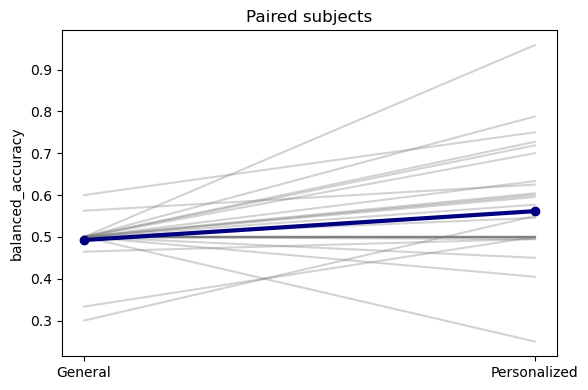

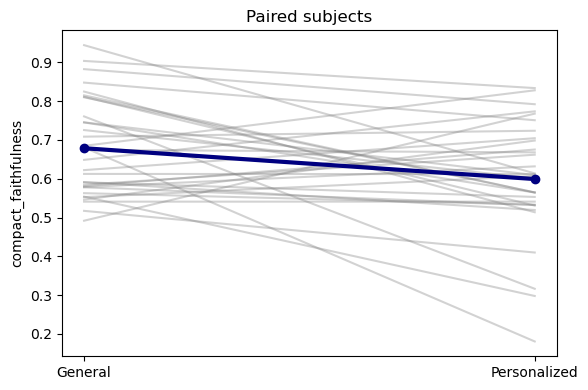

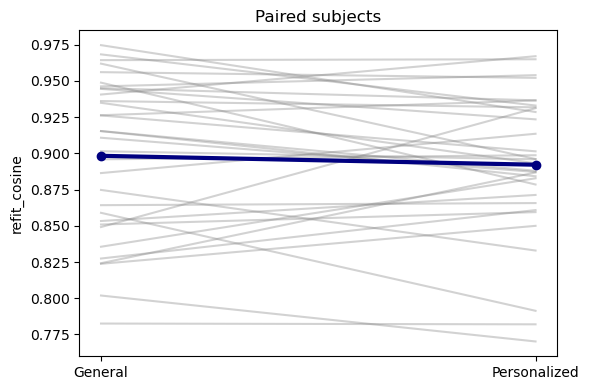

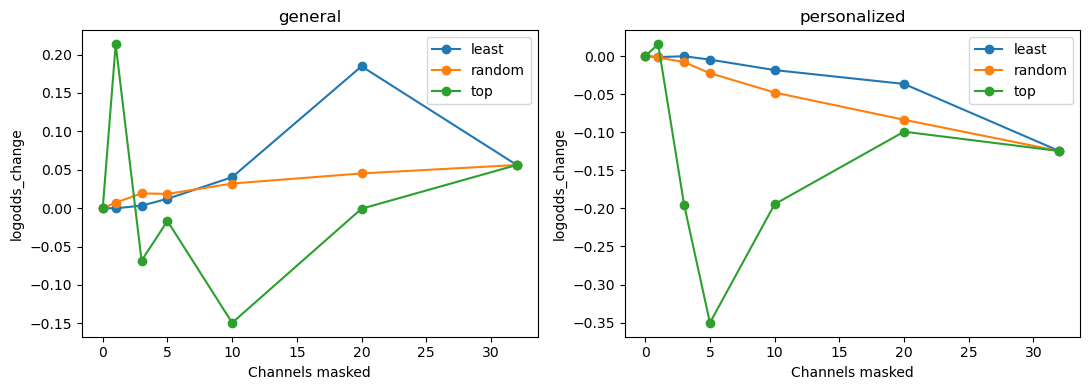

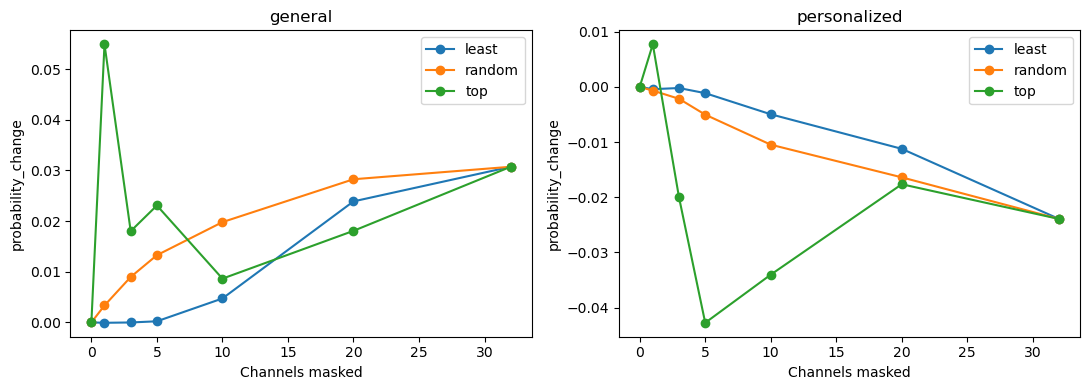

# Exploratory findings

Compact five-channel faithfulness improvement supported: False

Refit cosine stability improvement supported: False

Exploratory performance noninferiority criterion met (margin 0.03): True

Interpret effect sizes, absolute prediction performance and controls; endpoints with zero valid subjects are not assessable.

These tests concern compact explanatory coverage and frozen-preprocessing refit stability.

They do not establish improved full-SHAP exactness, physiological causality, or original EEG authenticity.

Failure to support improvement is a valid result; do not select tests retrospectively.

              metric  subjects  general_mean  personalized_mean  mean_delta  ci95_low  ci95_high  one_sided95_lower  signflip_p  improved  tied  degraded  holm_p_primary
compact_faithfulness        32      0.678558           0.599154   -0.079404 -0.141044  -0.019067          -0.131222    0.016249        11     0        21        0.032498
        refit_cosine        32 

In [7]:
def paired_statistics(results):
    rng=np.random.default_rng(SEED+900000);rows=[]
    for metric in ['compact_faithfulness','refit_cosine','refit_top5_overlap','balanced_accuracy','macro_f1','roc_auc']:
        w=results[results.model.isin(['general','personalized'])].pivot(index='subject',columns='model',values=metric).dropna()
        d=(w.personalized-w.general).to_numpy();n=len(d)
        if not n:
            rows.append({'metric':metric,'subjects':0,**{k:np.nan for k in ['general_mean','personalized_mean','mean_delta','ci95_low','ci95_high','one_sided95_lower','signflip_p','improved','tied','degraded']}})
            continue
        boot=rng.choice(d,size=(STATS_RESAMPLES,n),replace=True).mean(axis=1)
        signs=rng.choice([-1,1],size=(STATS_RESAMPLES,n))
        p=(1+np.sum(np.abs((signs*d).mean(axis=1))>=abs(d.mean())-1e-14))/(STATS_RESAMPLES+1)
        rows.append({'metric':metric,'subjects':n,'general_mean':w.general.mean(),'personalized_mean':w.personalized.mean(),
          'mean_delta':d.mean(),'ci95_low':np.quantile(boot,.025),'ci95_high':np.quantile(boot,.975),
          'one_sided95_lower':np.quantile(boot,.05),'signflip_p':p,'improved':int((d>1e-10).sum()),
          'tied':int((np.abs(d)<=1e-10).sum()),'degraded':int((d< -1e-10).sum())})
    summary=pd.DataFrame(rows);summary['holm_p_primary']=np.nan
    idx=summary.index[summary.metric.isin(['compact_faithfulness','refit_cosine']) & summary.signflip_p.notna()].to_numpy()
    order=idx[np.argsort(summary.loc[idx,'signflip_p'].to_numpy())]
    corrected=np.minimum(1,np.maximum.accumulate(summary.loc[order,'signflip_p'].to_numpy()*(len(order)-np.arange(len(order)))))
    summary.loc[order,'holm_p_primary']=corrected
    return summary

summary=paired_statistics(results)
summary.to_csv(OUT/'paired_summary.csv',index=False)
display(summary)
control=outputs['shuffled_label_controls'].groupby('subject')[['balanced_accuracy','roc_auc','compact_faithfulness']].mean()
true=results[results.model=='personalized'].set_index('subject')
control_comparison=true[['balanced_accuracy','roc_auc','compact_faithfulness']].join(control,rsuffix='_shuffled_mean')
control_comparison.to_csv(OUT/'correct_vs_shuffled_calibration.csv')
for metric in ['balanced_accuracy','compact_faithfulness','refit_cosine']:
    w=results[results.model.isin(['general','personalized'])].pivot(index='subject',columns='model',values=metric)
    fig,ax=plt.subplots(figsize=(6,4))
    for _,r in w.iterrows():ax.plot([0,1],[r.general,r.personalized],color='gray',alpha=.35)
    ax.plot([0,1],[w.general.mean(),w.personalized.mean()],color='navy',marker='o',linewidth=3)
    ax.set(xticks=[0,1],xticklabels=['General','Personalized'],ylabel=metric,title='Paired subjects')
    fig.tight_layout();fig.savefig(OUT/f'paired_{metric}.png',dpi=160);plt.show()
for scale in ['logodds_change','probability_change']:
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for ax,name in zip(axes,['general','personalized']):
        part=outputs['deletion_curves']
        part=part[part.model==name].groupby(['order','k'])[scale].mean().reset_index()
        for kind,g in part.groupby('order'):ax.plot(g.k,g[scale],marker='o',label=kind)
        ax.set(title=name,xlabel='Channels masked',ylabel=scale);ax.legend()
    fig.tight_layout();fig.savefig(OUT/f'deletion_{scale}.png',dpi=160);plt.show()

config={k:globals()[k] for k in ['FS','BASELINE_SECONDS','SKIP_STIMULUS_SECONDS','CORRELATION_THRESHOLD',
  'CALIBRATION_TRIALS','CALIBRATION_WEIGHT','C_GRID','INNER_FOLDS','BOOTSTRAP_REPEATS','SHUFFLE_REPEATS',
  'PERTURBATION_REPEATS','TOP_CHANNELS','MASK_PROBABILITY','SEED','NONINFERIORITY_MARGIN','STATS_RESAMPLES']}
config.update({'feature_count':128,'split':'presentation trials 1–20 calibration; 21–40 test',
  'metadata_sha256':REFERENCE_SHA256,'label_source':'embedded supplied participant_ratings.xls',
  'signal_source':'user-provided unofficial DEAP; signal equivalence unverified',
  'versions':{'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'sklearn':sklearn.__version__}})
(OUT/'configuration.json').write_text(json.dumps(config,indent=2),encoding='utf-8')
lookup=summary.set_index('metric')
f=lookup.loc['compact_faithfulness'];s=lookup.loc['refit_cosine'];perf=lookup.loc['balanced_accuracy']
f_ok=bool(f.mean_delta>0 and f.holm_p_primary<.05)
s_ok=bool(s.mean_delta>0 and s.holm_p_primary<.05)
p_ok=bool(perf.one_sided95_lower> -NONINFERIORITY_MARGIN)
lines=['# Exploratory findings',
  f'Compact five-channel faithfulness improvement supported: {f_ok}',
  f'Refit cosine stability improvement supported: {s_ok}',
  f'Exploratory performance noninferiority criterion met (margin {NONINFERIORITY_MARGIN}): {p_ok}',
  'Interpret effect sizes, absolute prediction performance and controls; endpoints with zero valid subjects are not assessable.',
  'These tests concern compact explanatory coverage and frozen-preprocessing refit stability.',
  'They do not establish improved full-SHAP exactness, physiological causality, or original EEG authenticity.',
  'Failure to support improvement is a valid result; do not select tests retrospectively.',
  summary.to_string(index=False)]
report='\n\n'.join(lines)
(OUT/'findings.md').write_text(report,encoding='utf-8')
print(report)
print('Results:',OUT.resolve())

## Deliverables and limitations
Send back paired_summary.csv, subject_metrics.csv, correct_vs_shuffled_calibration.csv, refit_stability.csv, configuration.json, findings.md and signal_audit.csv. Plots are also useful; raw EEG and model files are not needed.

- Chronological calibration is one deployment-oriented split. If a test set has one class, BA/AUC are undefined and paired counts must be reported; do not rearrange trials to obtain a preferred outcome.
- Twenty calibration trials is substantial. Later budget comparisons should keep a fixed test set and use training-only tuning.
- Compact fidelity depends on masking assumptions. Its value may reflect concentration/cancellation of contributions, not an improved explanation algorithm.
- Bootstrap stability is conditional on fixed preprocessing and class counts; it does not measure human clarity or usefulness.
- Shuffled calibration may retain useful class proportions or distribution information. Compare with its actual distribution, not an assumed 50% outcome.
- Low general performance cannot distinguish cross-subject difficulty from poor features or altered/misaligned signals.
- After this evaluation is checked, a separately specified nonlinear model comparison can test model-family dependence.
- The full run includes source-only nested fitting, shuffled controls and 20 paired refits per person. Runtime depends on CPU. Progress prints once per subject; a checkpoint is written.
- Load only trusted pickle/joblib files.

References: [scikit-learn leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html), [SHAP LinearExplainer](https://shap.readthedocs.io/en/latest/generated/shap.LinearExplainer.html), [DEAP](https://www.eecs.qmul.ac.uk/mmv/datasets/deap/).